# DSCO 2026 — Main 3 | Full Data Science Analysis & Model Development

**Studi kasus:** *Student at-risk prediction* (klasifikasi biner `at_risk`).  
**Fokus eksperimen:** nilai skor `77` yang berulang pada `has_score=0`, missingness, interaksi aktivitas–submission, dan model ensemble LightGBM + CatBoost.  
**Model yang dipakai untuk submission:** **M3-02** dengan *group-specific thresholds* (`has_score=0`: **0.420**, `has_score=1`: **0.370**).

> **Status dokumentasi:** notebook ini adalah **rekonstruksi dokumentasi lengkap dari eksperimen Main 3 yang benar-benar pernah dijalankan**. Kode pipeline berasal dari notebook Main 3 asli, bukan eksperimen baru. Bagian EDA visual dan pelaporan ditambahkan untuk membuat alurnya dapat dibaca sendiri. Hasil historis yang tercatat ≠ metrik yang dihitung ulang setelah training. Data mentah tidak ditimpa.

**Skor historis yang diketahui:** F1 OOF M3-02 = **0.774403** (threshold grup yang dipilih pada OOF), F1 *threshold cross-fit diagnostic* = **0.772923**, ROC AUC OOF = **0.845422**. Skor Kaggle yang pernah dilaporkan: **0.78393**; screenshot akhir menampilkan angka tambahan **0.78000**. Angka leaderboard bukan keluaran evaluasi notebook ini, dan posisi kolom Kaggle perlu dilihat pada layar lengkap untuk memastikan jenis skor.

### Alur notebook
1. Data understanding & audit kualitas → 2. EDA visual → 3. Audit skor dan aktivitas → 4. Cleaning → 5. Feature engineering → 6. Rancangan eksperimen → 7. Training 5-fold → 8. Evaluasi & error analysis → 9. Reproduksi submission & export laporan.

## 0. Protokol reproduksibilitas & batasan

- Sumber data: `train.csv`, `test.csv`, `sample_submission.csv`. Letakkan notebook ini di folder proyek atau subfolder; loader akan mencari file ke folder induk.
- Target: `at_risk` (0/1); identifier `id` **tidak** dilatih sebagai fitur. Seluruh grafik yang memakai `at_risk` hanya menggunakan train.
- Cross-validation: 5-fold **StratifiedKFold** (`shuffle=True`, `random_state=42`), LightGBM/ CatBoost blend **75%/25%**, CPU.
- Mode default `TRAIN_MODE='winner'` menjalankan **M3-02 saja** sehingga lebih hemat waktu. Ubah menjadi `'all'` untuk mengulang kelima run historis M3-00/01/02/03/05. M3-04 adalah eksperimen threshold, bukan model tambahan.
- **Hindari klaim source-proven:** skor 77 dan signature aktivitas *sangat mencurigakan*, tetapi asal-usul placeholder dan ketersediaan skor di cutoff belum terverifikasi dari generator data. Pemetaan GGG→M07 adalah keputusan pipeline historis dan **belum terverifikasi sebagai kebenaran sumber**.
- Sebuah *rerun* dapat memberikan probabilitas sedikit berbeda akibat versi pustaka/hardware. File submission historis tidak ditimpa; jika ditemukan di folder proyek, labelnya dibandingkan.

In [1]:
# 1. Load data asli dan siapkan folder laporan
from pathlib import Path
import random

import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
TARGET = "at_risk"
ID_COL = "id"

random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "train.csv").is_file()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("train.csv tidak ditemukan di folder kerja atau folder induknya.")

OUTPUT_DIR = DATA_DIR / "main3_full_analysis_outputs"
EDA_DIR = OUTPUT_DIR / "eda"
FIG_DIR = OUTPUT_DIR / "figures"
for folder in (OUTPUT_DIR, EDA_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_PATH = DATA_DIR / "sample_submission.csv"

train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)
sample_submission = pd.read_csv(SAMPLE_PATH)

assert TARGET in train.columns and TARGET not in test.columns
assert ID_COL in train.columns and ID_COL in test.columns
assert sample_submission.columns.tolist() == [ID_COL, TARGET]

for name, df in [
    ("train", train),
    ("test", test),
    ("sample_submission", sample_submission),
]:
    print(f"\n{name}: shape={df.shape}, memory={df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print("\nDtypes:")
    print(df.dtypes.to_string())
    print("\nHead:")
    display(df.head())


train: shape=(26086, 64), memory=23.43 MB

Dtypes:
id                                           int64
code_module                                 object
code_presentation                           object
gender                                      object
region                                      object
highest_education                           object
imd_band                                    object
age_band                                    object
num_of_prev_attempts                         int64
studied_credits                              int64
disability                                  object
module_presentation_length                   int64
registration_days_from_start                 int64
assessments_due_total                        int64
assessments_due_Assessment_1                 int64
assessments_due_Assessment_2                 int64
submitted_count                              int64
late_submission_count                        int64
avg_score                     

,id,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,week4_interactions,interaction_trend,early_interactions,late_interactions,late_to_early_interactions_ratio,avg_interactions_per_active_day,active_weeks,avg_interactions_per_active_week,activity_span_days,at_risk
0,1,M01,P12,M,Region1,HE Qualification,90-100%,55<=,0,240,...,0,-46.9,203,100,0.492611,43.285714,3,101.00,18,0
1,2,M01,P12,F,Region6,HE Qualification,20-30%,35-55,0,60,...,125,-17.9,241,162,0.672199,33.583333,4,100.75,28,0
2,3,M01,P12,F,region2,A Level,30-40%,35-55,0,60,...,0,-39.3,179,0,0.000000,29.833333,2,89.50,8,1
3,4,M01,P12,F,Region 10,A Level,50-60%,35-55,0,60,...,41,1.1,176,149,0.846591,19.117647,4,81.25,27,0
4,5,M01,P12,F,Region9,Lower Than A Level,50-60%,0-35,0,60,...,58,-8.8,177,95,0.536723,17.000000,4,68.00,25,0



test: shape=(6502, 63), memory=5.79 MB

Dtypes:
id                                           int64
code_module                                 object
code_presentation                           object
gender                                      object
region                                      object
highest_education                           object
imd_band                                    object
age_band                                    object
num_of_prev_attempts                         int64
studied_credits                              int64
disability                                  object
module_presentation_length                   int64
registration_days_from_start                 int64
assessments_due_total                        int64
assessments_due_Assessment_1                 int64
assessments_due_Assessment_2                 int64
submitted_count                              int64
late_submission_count                        int64
avg_score                        

,id,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,week3_interactions,week4_interactions,interaction_trend,early_interactions,late_interactions,late_to_early_interactions_ratio,avg_interactions_per_active_day,active_weeks,avg_interactions_per_active_week,activity_span_days
0,26092,M01,P12,F,Region9,A level,60-70%,35-55,0,60,...,129,1,-26.0,180,130,0.722222,28.181818,4,77.50,23
1,26093,M01,P12,M,Region12,A level,20-30%,0-35,0,60,...,49,16,-1.9,42,65,1.547619,8.916667,4,26.75,25
2,26094,M01,P12,M,Region13,Lower Than A Level,80-90%,35-55,0,60,...,310,123,-38.1,696,433,0.622126,59.421053,4,282.25,28
3,26095,M01,P12,F,Region 3,A level,40-50%,0-35,0,180,...,20,108,17.2,128,128,1.000000,17.066667,4,64.00,27
4,26096,M01,P12,M,Region 4,Lower Than A Level,60-70%,0-35,0,120,...,131,9,-16.1,155,140,0.903226,13.409091,4,73.75,28



sample_submission: shape=(6502, 2), memory=0.10 MB

Dtypes:
id         int64
at_risk    int64

Head:


,id,at_risk
0,26092,0
1,26093,0
2,26094,0
3,26095,0
4,26096,0


In [2]:
# 2. Kontrak data, versi lingkungan, dan checksum (tidak mengubah dataset)
import hashlib, platform, importlib.metadata, json
from IPython.display import display, Markdown

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

assert train[ID_COL].is_unique and test[ID_COL].is_unique
assert not train[ID_COL].isin(test[ID_COL]).any()
assert sample_submission[ID_COL].astype(str).tolist() == test[ID_COL].astype(str).tolist()
assert train[TARGET].notna().all() and set(train[TARGET].unique()).issubset({0, 1})
assert set(train.columns) - {TARGET} == set(test.columns)

RUN_INPUT_MANIFEST = {
    "train_sha256": sha256(TRAIN_PATH),
    "test_sha256": sha256(TEST_PATH),
    "sample_submission_sha256": sha256(SAMPLE_PATH),
    "train_rows": int(len(train)), "test_rows": int(len(test)),
    "python": platform.python_version(),
}
for pkg in ("numpy", "pandas", "scikit-learn", "lightgbm", "catboost"):
    try: RUN_INPUT_MANIFEST[pkg] = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError: RUN_INPUT_MANIFEST[pkg] = "NOT INSTALLED"
(OUTPUT_DIR / "input_manifest.json").write_text(json.dumps(RUN_INPUT_MANIFEST, indent=2), encoding="utf-8")
display(pd.Series(RUN_INPUT_MANIFEST, name="value").to_frame())

,value
train_sha256,1d65730e2f8627089cdb4258941324ef0c5ac0d3d0c580...
test_sha256,7bcd123cefe6fb5329f06a5c6bc1aa3bd7ffe58fe9d275...
sample_submission_sha256,0826a49b91f75d672f1fd9a61a491126f67803a988dcc3...
train_rows,26086
test_rows,6502
python,3.10.11
numpy,2.2.6
pandas,2.3.3
scikit-learn,1.7.2
lightgbm,4.7.0


## 1. Data understanding — siapa mahasiswa yang diprediksi?

**Pertanyaan EDA:** apakah distribusi label seimbang, apakah populasi `has_score=0` berbeda dari scored, apakah proporsi mahasiswa tanpa skor berubah di train/test, dan modul mana yang sulit? Data memiliki kira-kira 26 ribu baris train dan 6,5 ribu baris test pada eksperimen asli; angka aktual selalu dihitung ulang.

Catatan interpretasi: *risk rate* kelompok adalah **asosiasi observasional**; label tidak dipakai untuk mengisi fitur. Perbandingan train-test tidak boleh mengandalkan label test yang tidak tersedia.

,dataset,n,features,score_0,score_1,target_rate
0,train,26086,62,10046,16040,0.527218
1,test,6502,62,2636,3866,NaN


,has_score,n,risk_count,risk_rate
0,0,10046,7216,0.718296
1,1,16040,6537,0.407544


,code_module,n,risk_rate
1,M02,6368,0.523084
3,M04,6303,0.523878
5,M06,5066,0.582511
2,M03,3568,0.619955
4,M05,2343,0.439181
6,M07,1836,0.405773
0,M01,602,0.303987


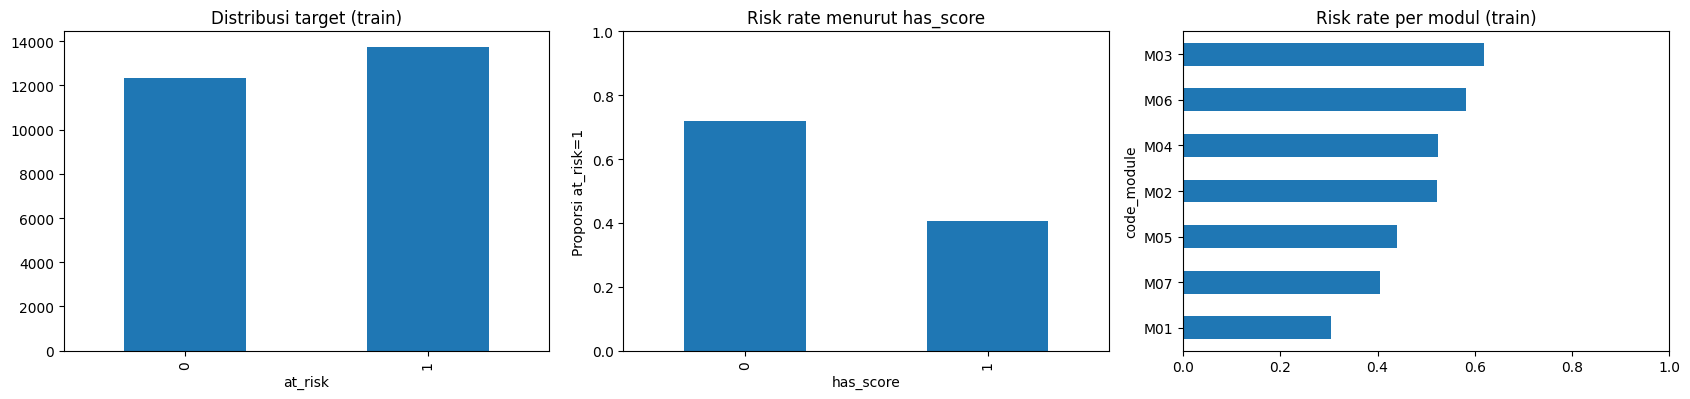

In [3]:
# 3. Ringkasan target, grup skor, modul dan train/test
import matplotlib.pyplot as plt
from IPython.display import display

def result_table(df, label):
    print(f"{label}: {len(df):,} baris × {len(df.columns)} kolom")
    return df

summary = pd.DataFrame([
    {"dataset":"train", "n":len(train), "features":len(train.columns)-2,
     "score_0":int(train['has_score'].eq(0).sum()), "score_1":int(train['has_score'].eq(1).sum()),
     "target_rate":float(train[TARGET].mean())},
    {"dataset":"test", "n":len(test), "features":len(test.columns)-1,
     "score_0":int(test['has_score'].eq(0).sum()), "score_1":int(test['has_score'].eq(1).sum()),
     "target_rate":np.nan},
])
score_risk = (train.groupby('has_score')[TARGET]
              .agg(n='size', risk_count='sum', risk_rate='mean').reset_index())
module_risk = (train.groupby('code_module')[TARGET]
               .agg(n='size', risk_rate='mean').reset_index().sort_values('n', ascending=False))
display(summary, score_risk, module_risk)
summary.to_csv(OUTPUT_DIR/'eda_dataset_summary.csv',index=False)
score_risk.to_csv(OUTPUT_DIR/'eda_score_group_risk.csv',index=False)
module_risk.to_csv(OUTPUT_DIR/'eda_module_risk.csv',index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.1))
train[TARGET].value_counts().sort_index().plot.bar(ax=axes[0]); axes[0].set_title('Distribusi target (train)'); axes[0].set_xlabel('at_risk')
score_risk.set_index('has_score')['risk_rate'].plot.bar(ax=axes[1]); axes[1].set_title('Risk rate menurut has_score'); axes[1].set_ylabel('Proporsi at_risk=1'); axes[1].set_ylim(0,1)
module_risk.sort_values('risk_rate').set_index('code_module')['risk_rate'].plot.barh(ax=axes[2]); axes[2].set_title('Risk rate per modul (train)'); axes[2].set_xlim(0,1)
plt.tight_layout(); plt.savefig(FIG_DIR/'01_target_and_groups.png',dpi=160,bbox_inches='tight'); plt.show()

,dataset,column,has_score,n,n_unique,count_77,fraction_77
0,train,avg_score,0,10046,1,10046,1.000000
1,train,avg_score,1,16040,163,196,0.012219
2,train,median_score,0,10046,1,10046,1.000000
3,train,median_score,1,16040,163,196,0.012219
4,train,min_score,0,10046,1,10046,1.000000
5,train,min_score,1,16040,95,222,0.013840
6,train,max_score,0,10046,1,10046,1.000000
7,train,max_score,1,16040,94,215,0.013404
8,train,score_Assessment_2,0,10046,1,10046,1.000000
9,train,score_Assessment_2,1,16040,94,2910,0.181421


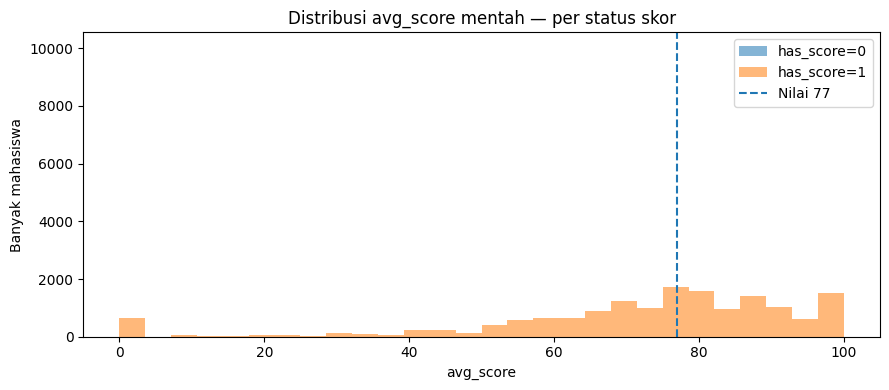

In [4]:
# 4. Exploratory analysis: skor yang diamati vs kandidat placeholder
scores = [c for c in ['avg_score', 'median_score', 'min_score','max_score','score_Assessment_2'] if c in train]
score_pattern_rows=[]
for dataset,frame in [('train',train), ('test',test)]:
    for c in scores:
        for group in (0,1):
            values=pd.to_numeric(frame.loc[frame['has_score'].eq(group),c],errors='coerce')
            score_pattern_rows.append(dict(dataset=dataset, column=c, has_score=group,n=len(values),
                                           n_unique=values.nunique(dropna=False),count_77=int(values.eq(77).sum()),
                                           fraction_77=float(values.eq(77).mean()) if len(values) else np.nan))
score_patterns=pd.DataFrame(score_pattern_rows)
display(score_patterns)
score_patterns.to_csv(OUTPUT_DIR/'eda_score_patterns.csv',index=False)

fig, ax=plt.subplots(figsize=(9,4))
for group in (0,1):
    values=pd.to_numeric(train.loc[train['has_score'].eq(group),'avg_score'],errors='coerce')
    ax.hist(values.dropna(),bins=28,alpha=0.55,label=f'has_score={group}')
ax.axvline(77,linestyle='--',linewidth=1.5,label='Nilai 77')
ax.set(title='Distribusi avg_score mentah — per status skor',xlabel='avg_score',ylabel='Banyak mahasiswa')
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR/'02_score77.png',dpi=160,bbox_inches='tight'); plt.show()

,dataset,n,mismatch,percentage
0,train,26086,3737,14.325692
1,test,6502,947,14.564749


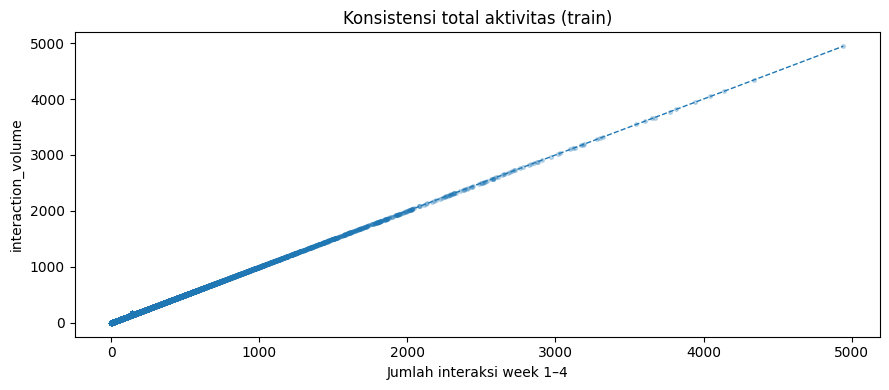

In [5]:
# 5. Aktivitas mingguan vs total: konsistensi belum membuktikan data palsu
WEEK_FIELDS=[f'week{i}_interactions' for i in range(1,5)]
def activity_issue(frame):
    w=frame[WEEK_FIELDS].apply(pd.to_numeric,errors='coerce')
    volume=pd.to_numeric(frame['interaction_volume'],errors='coerce')
    valid=w.notna().all(axis=1)&volume.notna()
    mismatch=valid & ~np.isclose(volume,w.sum(axis=1),rtol=1e-6,atol=1e-5)
    return pd.Series(mismatch,index=frame.index)
train_mismatch=activity_issue(train);test_mismatch=activity_issue(test)
act_summary=pd.DataFrame([
    dict(dataset='train',n=len(train),mismatch=int(train_mismatch.sum()),percentage=100*train_mismatch.mean()),
    dict(dataset='test',n=len(test),mismatch=int(test_mismatch.sum()),percentage=100*test_mismatch.mean()),
])
display(act_summary)
act_summary.to_csv(OUTPUT_DIR/'eda_activity_mismatch.csv',index=False)

fig, ax=plt.subplots(figsize=(9,4))
figures=(train[WEEK_FIELDS].apply(pd.to_numeric,errors='coerce').sum(axis=1))
ax.scatter(figures, pd.to_numeric(train['interaction_volume'],errors='coerce'),s=7,alpha=.25)
lim=max(float(figures.max()),float(train['interaction_volume'].max()))
ax.plot([0,lim],[0,lim],linestyle='--',linewidth=1)
ax.set(xlabel='Jumlah interaksi week 1–4',ylabel='interaction_volume',title='Konsistensi total aktivitas (train)')
plt.tight_layout();plt.savefig(FIG_DIR/'03_activity_consistency.png',dpi=160,bbox_inches='tight');plt.show()

,column,train_unique,test_unique,unseen_test_categories,total_variation_distance
2,highest_education,5,5,1,0.439469
0,code_module,7,8,1,0.063359
4,has_score,2,2,0,0.020303
3,imd_band,11,11,0,0.020117
1,code_presentation,4,4,0,0.007555


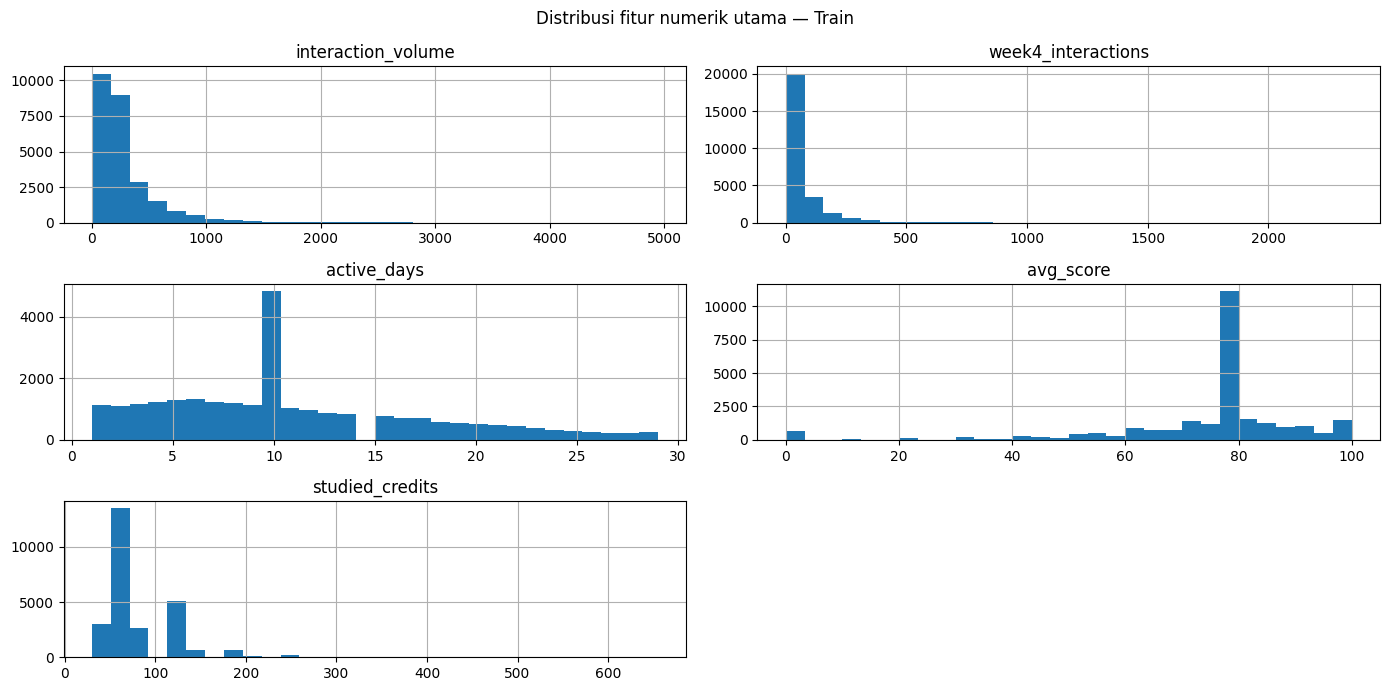

In [6]:
# 6. Distribution shift sederhana: kategori utama dan numeric overview
cats_to_compare=[c for c in ['code_module','code_presentation','highest_education','imd_band','has_score'] if c in train]
shift_rows=[]
for col in cats_to_compare:
    p=train[col].fillna('Missing').astype(str).value_counts(normalize=True)
    q=test[col].fillna('Missing').astype(str).value_counts(normalize=True)
    shift_rows.append(dict(column=col,train_unique=p.size,test_unique=q.size,
        unseen_test_categories=len(set(q.index)-set(p.index)),
        total_variation_distance=float(.5*(p.reindex(p.index.union(q.index),fill_value=0)-q.reindex(p.index.union(q.index),fill_value=0)).abs().sum())))
shift_summary=pd.DataFrame(shift_rows).sort_values('total_variation_distance',ascending=False)
display(shift_summary)
shift_summary.to_csv(OUTPUT_DIR/'eda_shift_summary.csv',index=False)

numbers=[c for c in ['interaction_volume','week4_interactions','active_days','avg_score','studied_credits'] if c in train]
if numbers:
    train[numbers].apply(pd.to_numeric,errors='coerce').hist(bins=30,figsize=(14,7))
    plt.suptitle('Distribusi fitur numerik utama — Train');plt.tight_layout()
    plt.savefig(FIG_DIR/'04_numeric_distributions.png',dpi=160,bbox_inches='tight');plt.show()

### Temuan EDA yang menjadi dasar eksperimen

- Pada audit asli, **10.046 train** dan **2.636 test** memiliki `has_score=0`, dan nilai `avg_score` berulang **77**. Angka 77 pada kelompok yang *punya* skor tidak boleh dianggap otomatis missing.
- Pada audit asli, **3.737 train** dan **947 test** memiliki inkonsistensi volume terhadap empat minggu. Signature umum: total **182** vs penjumlahan mingguan **141**. Nilai yang tidak konsisten bisa muncul karena definisi metrik yang berbeda, bukan selalu kesalahan.
- `GGG` muncul pada **372 test** dan tidak ada di train. Pipeline Main 3 historis menyamakannya dengan `M07`, **tetapi identitas modul belum dibuktikan dari sumber independen**.
- Dataset memuat kategori seperti `imd_band='-'/'?'`, penulisan `A Level`/`A level`, dan `region2`/`Region 2`. Ini alasan normalisasi token/format.

Bagian berikut memakai kode audit rinci **asli** yang pernah dijalankan pada Main 3, bukan mengganti hasil observasinya dengan kesimpulan buatan.

In [7]:
# 7. Audit lanjutan seluruh kolom — kode historis Main 3
import re
import unicodedata
from collections import Counter

from scipy.stats import ks_2samp
from pandas.api.types import is_numeric_dtype

# Baca ulang sebagai teks agar "-", "?", spasi, dan format asli tidak hilang.
raw_data = {
    "train": pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False, na_filter=False),
    "test": pd.read_csv(TEST_PATH, dtype=str, keep_default_na=False, na_filter=False),
}
assert raw_data["train"].columns.tolist() == train.columns.tolist()
assert raw_data["test"].columns.tolist() == test.columns.tolist()

def normalize_text(value):
    value = unicodedata.normalize("NFKC", str(value))
    return re.sub(r"\s+", " ", value.strip())

missing_tokens = {
    "", "-", "?", "na", "n/a", "n.a.", "null", "none",
    "nan", "missing", "unknown", "not available", "not applicable",
}

def is_hidden_missing(value):
    value = normalize_text(value)
    return value.casefold() in missing_tokens or bool(re.fullmatch(r"[^\w\s]+", value))

def compact_key(value):
    return re.sub(r"[^a-z0-9]+", "", normalize_text(value).casefold())

def md_table(df):
    if df.empty:
        return "_Tidak ada._"
    def fmt(value):
        if pd.isna(value):
            return ""
        if isinstance(value, (float, np.floating)):
            return f"{value:.4f}"
        return str(value).replace("|", "\\|").replace("\n", " ")
    rows = [[fmt(v) for v in row] for row in df.itertuples(index=False, name=None)]
    return "\n".join([
        "| " + " | ".join(map(str, df.columns)) + " |",
        "| " + " | ".join(["---"] * len(df.columns)) + " |",
        *["| " + " | ".join(row) + " |" for row in rows],
    ])

normalized = {
    name: df.apply(lambda col: col.map(normalize_text))
    for name, df in raw_data.items()
}
hidden_missing = {
    name: df.apply(lambda col: col.map(is_hidden_missing))
    for name, df in normalized.items()
}

# Tentukan tipe yang diharapkan dari train, dibantu rasio nilai yang dapat dibaca sebagai angka.
column_roles = {}
type_rows = []
for col in raw_data["train"].columns:
    values = pd.concat(
        [normalized[name][col][~hidden_missing[name][col]]
         for name in raw_data if col in raw_data[name]],
        ignore_index=True,
    )
    numeric_ratio = pd.to_numeric(values, errors="coerce").notna().mean() if len(values) else 0
    if col == ID_COL:
        role = "ID"
    elif col == TARGET:
        role = "target"
    elif is_numeric_dtype(train[col]) or numeric_ratio >= 0.95:
        role = "numerik"
    else:
        role = "kategorikal"
    column_roles[col] = role
    type_rows.append({
        "kolom": col,
        "dtype_pandas": str(train[col].dtype),
        "peran": role,
        "unik_train": raw_data["train"][col].nunique(),
        "rasio_dapat_dibaca_angka": numeric_ratio,
        "missing_terbaca_pandas": int(train[col].isna().sum()),
        "missing_mentah_termasuk_placeholder": int(hidden_missing["train"][col].sum()),
    })
eda1_types = pd.DataFrame(type_rows)

numeric_cols = [c for c, role in column_roles.items() if role == "numerik"]
feature_cols = [c for c in train.columns if c not in [ID_COL, TARGET]]
numeric_data = {
    name: pd.DataFrame({
        col: pd.to_numeric(
            normalized[name][col].mask(hidden_missing[name][col]),
            errors="coerce",
        )
        for col in numeric_cols if col in normalized[name]
    })
    for name in raw_data
}

issue_rows = []
def record_issue(dataset, col, issue, mask):
    mask = pd.Series(mask, index=raw_data[dataset].index).fillna(False).astype(bool)
    count = int(mask.sum())
    if count == 0:
        return
    examples = [
        f"{row[ID_COL]}:{row[col]!r}"
        for _, row in raw_data[dataset].loc[mask, [ID_COL, col]].head(5).iterrows()
    ]
    issue_rows.append({
        "dataset": dataset, "kolom": col, "masalah": issue,
        "jumlah": count, "persen": 100 * count / len(mask),
        "contoh_ID:nilai": "; ".join(examples),
    })

# Audit setiap kolom, termasuk ID dan target.
audit_rows = []
placeholder_rows = []
for dataset, df in raw_data.items():
    for col in df.columns:
        raw_col = df[col]
        norm_col = normalized[dataset][col]
        missing_mask = hidden_missing[dataset][col]
        whitespace_mask = (~missing_mask) & raw_col.ne(norm_col)
        malformed_mask = pd.Series(False, index=df.index)

        if col in numeric_data[dataset]:
            malformed_mask = (~missing_mask) & numeric_data[dataset][col].isna()
            record_issue(dataset, col, "angka tidak dapat diparse", malformed_mask)

        record_issue(dataset, col, "placeholder / tanda baca sebagai missing", missing_mask)
        record_issue(dataset, col, "spasi atau Unicode tidak konsisten", whitespace_mask)

        tokens = Counter(norm_col[missing_mask])
        if tokens:
            placeholder_rows.append({
                "dataset": dataset, "kolom": col,
                "jumlah": int(missing_mask.sum()),
                "token_dan_frekuensi": "; ".join(
                    f"{token!r}={count}" for token, count in tokens.most_common(10)
                ),
            })

        audit_rows.append({
            "dataset": dataset, "kolom": col, "peran": column_roles[col],
            "baris": len(df),
            "unik_raw": raw_col.nunique(),
            "missing_tersembunyi": int(missing_mask.sum()),
            "format_spasi_Unicode": int(whitespace_mask.sum()),
            "angka_tidak_valid": int(malformed_mask.sum()),
        })

eda1_audit = pd.DataFrame(audit_rows)
eda1_placeholders = pd.DataFrame(placeholder_rows)

# Nilai kategori yang sebenarnya sama setelah mengabaikan kapitalisasi, spasi, dan tanda baca.
variant_rows = []
for col in [c for c in feature_cols if column_roles[c] == "kategorikal"]:
    all_values = pd.concat([
        normalized[name][col][~hidden_missing[name][col]]
        for name in raw_data
    ], ignore_index=True)
    groups = {}
    for value, count in all_values.value_counts().items():
        groups.setdefault(compact_key(value), []).append((value, int(count)))
    for key, variants in groups.items():
        if len(variants) > 1:
            variant_rows.append({
                "kolom": col, "kunci_normalisasi": key,
                "jumlah_variannya": len(variants),
                "nilai_dan_frekuensi": "; ".join(
                    f"{value!r}={count}" for value, count in variants
                ),
            })
eda1_category_variants = pd.DataFrame(variant_rows)

# Pola format yang dapat diperiksa dari definisi kolom.
format_rules = {
    "code_module": r"M\d{2}",
    "code_presentation": r"P\d{2}",
    "region": r"Region\d+",
    "gender": r"[MF]",
    "disability": r"[NY]",
    "imd_band": r"\d{1,2}-\d{1,3}%",
    "age_band": r"(?:0-35|35-55|55<=)",
}
for dataset in raw_data:
    for col, pattern in format_rules.items():
        if col not in normalized[dataset]:
            continue
        valid = ~hidden_missing[dataset][col]
        bad = valid & ~normalized[dataset][col].str.fullmatch(pattern)
        record_issue(dataset, col, "format kategori berbeda dari pola kolom", bad)

# Kategori baru di test: penting untuk mendeteksi nilai seperti kode modul yang tidak ada di train.
novel_category_rows = []
for col in [c for c in feature_cols if column_roles[c] == "kategorikal"]:
    train_keys = {
        compact_key(v) for v in normalized["train"].loc[
            ~hidden_missing["train"][col], col
        ]
    }
    test_values = normalized["test"].loc[~hidden_missing["test"][col], col]
    novel = test_values[test_values.map(compact_key).map(lambda key: key not in train_keys)]
    if not novel.empty:
        novel_category_rows.append({
            "kolom": col, "jumlah_baris_test": len(novel),
            "nilai_baru": "; ".join(
                f"{v!r}={n}" for v, n in novel.value_counts().head(10).items()
            ),
        })
        record_issue(
            "test", col, "kategori tidak dijumpai di train",
            normalized["test"].index.isin(novel.index),
        )
eda1_novel_categories = pd.DataFrame(novel_category_rows)

# Batas berdasarkan definisi fitur; pelanggaran dicatat untuk ditinjau, bukan langsung dihapus.
bounds = {}
for col in numeric_cols:
    if col.startswith("score_") and col not in ["score_std", "score_trend"]:
        bounds[col] = (0, 100)
    elif col in ["avg_score", "median_score", "max_score", "min_score"]:
        bounds[col] = (0, 100)
    elif col.startswith("assessment_completion_rate"):
        bounds[col] = (0, 1)
    elif col in ["first_activity_day", "last_activity_day"]:
        bounds[col] = (0, 27)
    elif col == "active_days":
        bounds[col] = (0, 28)
    elif col == "active_weeks":
        bounds[col] = (0, 4)
    elif col in [
        "interaction_volume", "unique_sites", "unique_activity_types",
        "week1_interactions", "week2_interactions", "week3_interactions",
        "week4_interactions", "early_interactions", "late_interactions",
        "submitted_count", "late_submission_count", "assessments_due_total",
        "num_of_prev_attempts", "studied_credits", "score_std",
        "interaction_variability", "activity_span_days",
    ]:
        bounds[col] = (0, None)

for dataset, num in numeric_data.items():
    for col, (lower, upper) in bounds.items():
        if col not in num:
            continue
        bad = pd.Series(False, index=num.index)
        if lower is not None:
            bad |= num[col] < lower
        if upper is not None:
            bad |= num[col] > upper
        record_issue(dataset, col, f"di luar rentang [{lower}, {upper}]", bad)

# Puncak nilai numerik yang sangat dominan: kandidat nilai default, belum tentu missing.
spike_rows = []
for dataset, num in numeric_data.items():
    for col in [c for c in feature_cols if c in num]:
        values = num[col].dropna()
        if values.nunique() < 15 or values.empty:
            continue
        counts = values.value_counts()
        share = counts.iloc[0] / len(values)
        if share >= 0.10:
            spike_rows.append({
                "dataset": dataset, "kolom": col,
                "nilai_dominan": counts.index[0],
                "jumlah": int(counts.iloc[0]),
                "persen_dari_valid": 100 * share,
                "jumlah_nilai_unik": values.nunique(),
            })
eda1_numeric_spikes = pd.DataFrame(spike_rows)

# Missing bersyarat: nilai skor terisi ketika indikator menyatakan belum ada skor.
conditional_rows = []
score_related = [
    c for c in numeric_cols
    if c in ["avg_score", "median_score", "max_score", "min_score",
             "score_std", "score_trend", "weighted_score_total"]
    or c.startswith(("score_Assessment_", "weighted_score_Assessment_"))
]
for dataset, num in numeric_data.items():
    if "has_score" not in num:
        continue
    no_score = num["has_score"].eq(0)
    for col in score_related:
        if col not in num:
            continue
        observed = num.loc[no_score, col].dropna()
        if not observed.empty:
            top = observed.value_counts().head(3)
            conditional_rows.append({
                "dataset": dataset, "kondisi": "has_score = 0",
                "kolom": col, "terisi_saat_kondisi": len(observed),
                "persen_dari_kondisi": 100 * len(observed) / max(int(no_score.sum()), 1),
                "nilai_teratas": "; ".join(f"{v}={n}" for v, n in top.items()),
            })
eda1_conditional_missing = pd.DataFrame(conditional_rows)

# Periksa hubungan antarkolom yang seharusnya konsisten menurut definisinya.
consistency_rows = []
relations = [
    ("interaction_volume = jumlah minggu", "interaction_volume",
     ["week1_interactions", "week2_interactions", "week3_interactions", "week4_interactions"], "sum"),
    ("early_interactions = minggu 1+2", "early_interactions",
     ["week1_interactions", "week2_interactions"], "sum"),
    ("late_interactions = minggu 3+4", "late_interactions",
     ["week3_interactions", "week4_interactions"], "sum"),
    ("assessments_due_total = Assessment 1+2", "assessments_due_total",
     ["assessments_due_Assessment_1", "assessments_due_Assessment_2"], "sum"),
    ("activity_span_days = hari terakhir-pertama", "activity_span_days",
     ["last_activity_day", "first_activity_day"], "difference"),
    ("active_weeks = jumlah minggu aktif", "active_weeks",
     ["week1_interactions", "week2_interactions", "week3_interactions", "week4_interactions"], "active_weeks"),
    ("avg_daily_interactions = volume/hari aktif", "avg_daily_interactions",
     ["interaction_volume", "active_days"], "ratio"),
    ("avg_interactions_per_active_day = volume/hari aktif", "avg_interactions_per_active_day",
     ["interaction_volume", "active_days"], "ratio"),
    ("avg_interactions_per_active_week = volume/minggu aktif", "avg_interactions_per_active_week",
     ["interaction_volume", "active_weeks"], "ratio"),
]
for dataset, num in numeric_data.items():
    for label, actual_col, source_cols, method in relations:
        if not set([actual_col, *source_cols]).issubset(num.columns):
            continue
        valid = num[[actual_col, *source_cols]].notna().all(axis=1)
        if method == "sum":
            expected = num[source_cols].sum(axis=1)
        elif method == "difference":
            expected = num[source_cols[0]] - num[source_cols[1]]
        elif method == "active_weeks":
            expected = num[source_cols].gt(0).sum(axis=1)
        else:
            expected = num[source_cols[0]] / num[source_cols[1]].replace(0, np.nan)
            valid &= expected.notna()
        mismatch = valid & ~pd.Series(
            np.isclose(num[actual_col], expected, rtol=1e-6, atol=1e-5, equal_nan=True),
            index=num.index,
        )
        consistency_rows.append({
            "dataset": dataset, "aturan": label,
            "baris_dapat_diperiksa": int(valid.sum()),
            "tidak_konsisten": int(mismatch.sum()),
            "contoh_ID": ", ".join(
                raw_data[dataset].loc[mismatch, ID_COL].head(8).astype(str)
            ),
        })
        record_issue(dataset, actual_col, f"tidak konsisten: {label}", mismatch)
eda1_consistency = pd.DataFrame(consistency_rows)
eda1_issues = pd.DataFrame(issue_rows)

# Ringkasan per kolom mencakup semua jenis anomali yang ditemukan.
if not eda1_issues.empty:
    issue_totals = eda1_issues.groupby(["dataset", "kolom"])["jumlah"].sum()
    eda1_audit["jumlah_temuan_semua_jenis"] = [
        issue_totals.get((row.dataset, row.kolom), 0)
        for row in eda1_audit.itertuples()
    ]
else:
    eda1_audit["jumlah_temuan_semua_jenis"] = 0

# Missing efektif untuk EDA: placeholder dan angka yang gagal diparse.
effective_missing = {}
for dataset, df in raw_data.items():
    effective_missing[dataset] = pd.DataFrame({
        col: hidden_missing[dataset][col] | (
            numeric_data[dataset][col].isna() if col in numeric_data[dataset]
            else pd.Series(False, index=df.index)
        )
        for col in df.columns
    })

eda1_missing = pd.DataFrame([
    {
        "kolom": col,
        "missing_train_n": int(effective_missing["train"][col].sum()),
        "missing_train_pct": 100 * effective_missing["train"][col].mean(),
        "missing_test_n": int(effective_missing["test"][col].sum()),
        "missing_test_pct": 100 * effective_missing["test"][col].mean(),
    }
    for col in feature_cols
]).sort_values("missing_train_pct", ascending=False)

missing_cols = [c for c in feature_cols if effective_missing["train"][c].any()]
missing_flags = effective_missing["train"][missing_cols].astype("int8")
missing_corr = missing_flags.corr() if missing_cols else pd.DataFrame()
y = pd.to_numeric(train[TARGET], errors="raise")

missing_pattern_rows = []
for col in missing_cols:
    flag = missing_flags[col]
    target_corr = flag.corr(y) if flag.nunique() > 1 else np.nan
    peers = missing_corr[col].drop(index=col).dropna() if len(missing_cols) > 1 else pd.Series(dtype=float)
    peer = peers.abs().idxmax() if not peers.empty else ""
    missing_pattern_rows.append({
        "kolom": col,
        "korelasi_missing_target": target_corr,
        "missing_terkait": peer,
        "korelasi_antar_missing": peers.get(peer, np.nan),
    })
eda1_missing_patterns = pd.DataFrame(missing_pattern_rows)

numeric_rows = []
for col in [c for c in feature_cols if c in numeric_data["train"]]:
    s = numeric_data["train"][col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr, std = q3 - q1, s.std(ddof=0)
    numeric_rows.append({
        "kolom": col, "min": s.min(), "median": s.median(), "max": s.max(),
        "mean": s.mean(), "std": std, "skew": s.skew(), "kurtosis": s.kurt(),
        "outlier_IQR_pct": 100 * (
            ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() if iqr > 0 else 0
        ),
        "outlier_Z3_pct": 100 * (
            (((s - s.mean()).abs() / std) > 3).mean() if std > 0 else 0
        ),
    })
eda1_numeric = pd.DataFrame(numeric_rows)

duplicate_rows = pd.DataFrame([{
    "duplikat_baris_penuh": int(train.duplicated().sum()),
    "duplikat_ID_train": int(train[ID_COL].duplicated().sum()),
    "duplikat_ID_test": int(test[ID_COL].duplicated().sum()),
    "duplikat_fitur_tanpa_ID_target": int(train.duplicated(subset=feature_cols).sum()),
}])
constant_cols = [
    c for c in feature_cols
    if normalized["train"].loc[~effective_missing["train"][c], c].nunique() <= 1
]
quasi_constant = pd.DataFrame([
    {"kolom": c, "frekuensi_nilai_teratas": normalized["train"][c].value_counts(normalize=True).iloc[0]}
    for c in feature_cols
    if normalized["train"][c].nunique() > 1
    and normalized["train"][c].value_counts(normalize=True).iloc[0] >= 0.99
])
high_cardinality = eda1_types.loc[
    eda1_types["peran"].eq("kategorikal") & eda1_types["unik_train"].gt(50),
    ["kolom", "unik_train"],
]

target_dist = y.value_counts(dropna=False).sort_index().rename_axis(TARGET).reset_index(name="jumlah")
target_dist["persen"] = 100 * target_dist["jumlah"] / len(train)

drift_rows = []
for col in feature_cols:
    a_missing = effective_missing["train"][col]
    b_missing = effective_missing["test"][col]
    if column_roles[col] == "numerik":
        a = numeric_data["train"][col].dropna()
        b = numeric_data["test"][col].dropna()
        result = ks_2samp(a, b) if len(a) and len(b) else None
        metric = "KS"
        statistic = result.statistic if result else np.nan
    else:
        a = normalized["train"][col].mask(a_missing, "<MISSING>").value_counts(normalize=True)
        b = normalized["test"][col].mask(b_missing, "<MISSING>").value_counts(normalize=True)
        keys = a.index.union(b.index)
        metric = "total_variation"
        statistic = 0.5 * (
            a.reindex(keys, fill_value=0) - b.reindex(keys, fill_value=0)
        ).abs().sum()
    missing_delta = 100 * (b_missing.mean() - a_missing.mean())
    drift_rows.append({
        "kolom": col, "metrik": metric, "statistik": statistic,
        "delta_missing_pp": missing_delta,
        "indikasi_drift": bool(
            (pd.notna(statistic) and statistic >= 0.10) or abs(missing_delta) >= 5
        ),
    })
eda1_drift = pd.DataFrame(drift_rows).sort_values("statistik", ascending=False)

# Rekomendasi dibuat dari hasil audit, tanpa mengubah data pada tahap EDA.
skew_map = eda1_numeric.set_index("kolom")["skew"].to_dict() if not eda1_numeric.empty else {}
missing_corr_map = (
    eda1_missing_patterns.set_index("kolom")["korelasi_missing_target"].to_dict()
    if not eda1_missing_patterns.empty else {}
)
recommendation_rows = []
for col in train.columns:
    role = column_roles[col]
    missing_pct = 100 * effective_missing["train"][col].mean()
    corr = missing_corr_map.get(col, np.nan)
    if col == ID_COL:
        imputation, action = "tidak perlu", "pisahkan sebagai ID"
    elif col == TARGET:
        imputation, action = "tidak perlu", "pisahkan sebagai label"
    elif col in constant_cols:
        imputation, action = "tidak perlu", "hapus fitur konstan"
    elif role == "numerik":
        imputation = (
            "tidak perlu" if missing_pct == 0
            else "median" if abs(skew_map.get(col, 0)) >= 1
            else "mean"
        )
        action = "pertahankan; tinjau nilai dominan dan inkonsistensi"
    else:
        imputation = "kategori Missing" if missing_pct > 0 else "tidak perlu"
        action = "standarkan format kategori; pertahankan kategori baru sebagai unknown"
    recommendation_rows.append({
        "kolom": col, "peran": role,
        "missing_efektif_pct": missing_pct,
        "imputasi": imputation,
        "indikator_missing": bool(
            0 < missing_pct < 100
            and (missing_pct >= 10 or (pd.notna(corr) and abs(corr) >= 0.05))
        ),
        "aksi": action,
    })
eda1_recommendations = pd.DataFrame(recommendation_rows)

report_sections = [
    "# EDA Phase 1 — audit data mentah",
    "## Ringkasan dataset",
    md_table(pd.DataFrame([
        {"dataset": name, "baris": len(df), "kolom": df.shape[1],
         "memori_MB": df.memory_usage(deep=True).sum() / 1024**2}
        for name, df in raw_data.items()
    ])),
    "## Audit seluruh kolom",
    md_table(eda1_audit),
    "## Tipe, kardinalitas, dan missing yang tersembunyi",
    md_table(eda1_types),
    "## Token placeholder",
    md_table(eda1_placeholders),
    "## Variasi ejaan, kapitalisasi, spasi, dan tanda baca pada kategori",
    md_table(eda1_category_variants),
    "## Kategori baru pada test",
    md_table(eda1_novel_categories),
    "## Semua temuan format dan rentang, dengan contoh ID",
    md_table(eda1_issues.sort_values(["dataset", "kolom", "masalah"]) if not eda1_issues.empty else eda1_issues),
    "## Nilai numerik yang sangat dominan — kandidat default, belum otomatis missing",
    md_table(eda1_numeric_spikes),
    "## Nilai skor terisi ketika has_score = 0",
    md_table(eda1_conditional_missing),
    "## Konsistensi antarkolom",
    md_table(eda1_consistency),
    "## Missing efektif per kolom",
    md_table(eda1_missing),
    "## Hubungan antar-missing dan dengan target",
    md_table(eda1_missing_patterns),
    "Korelasi missing hanya menunjukkan asosiasi; MCAR/MAR/MNAR tidak dapat dipastikan dari data teramati saja.",
    "## Distribusi numerik dan outlier",
    md_table(eda1_numeric),
    "## Duplikat",
    md_table(duplicate_rows),
    "## Fitur konstan",
    ", ".join(constant_cols) if constant_cols else "_Tidak ada._",
    "## Fitur hampir konstan",
    md_table(quasi_constant),
    "## Kategorikal berkardinalitas tinggi",
    md_table(high_cardinality),
    "## Distribusi target",
    md_table(target_dist),
    "## Drift train–test",
    md_table(eda1_drift),
    "## Rekomendasi cleaning dan imputasi per kolom",
    md_table(eda1_recommendations),
    "Nilai dominan dan pelanggaran konsistensi perlu ditinjau sebelum diubah menjadi missing.",
]

eda1_report_path = EDA_DIR / "eda_phase1.md"
eda1_report_path.write_text("\n\n".join(report_sections) + "\n", encoding="utf-8")
print(f"Report tersimpan: {eda1_report_path}")
print("Audit lengkap telah ditulis ke Markdown; tidak dicetak seluruhnya agar output notebook ringkas.")

Report tersimpan: c:\Users\yosee\Documents\DSCO 2026\main3_full_analysis_outputs\eda\eda_phase1.md
Audit lengkap telah ditulis ke Markdown; tidak dicetak seluruhnya agar output notebook ringkas.


In [8]:
# 8. Audit skor, aktivitas, cutoff, dan kelompok — kode historis Main 3
from IPython.display import display

datasets = {"train": train, "test": test}
score_cols = [
    c for c in train.columns
    if "score" in c.lower() and c not in [TARGET, "has_score"]
]

def angka(df, col):
    return pd.to_numeric(df[col], errors="coerce")

def tabel_markdown(df):
    if df.empty:
        return "_Tidak ada._"
    def format_nilai(x):
        if pd.isna(x):
            return ""
        if isinstance(x, (float, np.floating)):
            return f"{x:.2f}"
        return str(x).replace("|", "\\|")
    rows = [[format_nilai(x) for x in row] for row in df.itertuples(index=False, name=None)]
    return "\n".join([
        "| " + " | ".join(df.columns) + " |",
        "| " + " | ".join(["---"] * len(df.columns)) + " |",
        *["| " + " | ".join(row) + " |" for row in rows],
    ])

score_rows = []
activity_rows = []
profile_rows = []
day_rows = []
group_rows = []

for dataset, df in datasets.items():
    has_score = angka(df, "has_score")
    no_score = has_score.eq(0)
    with_score = has_score.eq(1)

    # Apakah kolom skor memakai nilai tetap saat has_score=0?
    for col in score_cols:
        values = angka(df, col)
        subset = values[no_score]
        if subset.empty:
            continue
        top = subset.value_counts(dropna=False)
        top_value = top.index[0]
        score_rows.append({
            "dataset": dataset,
            "kolom": col,
            "baris_has_score_0": int(no_score.sum()),
            "nilai_unik_saat_has_score_0": subset.nunique(dropna=False),
            "nilai_tersering": top_value,
            "persen_nilai_tersering": 100 * top.iloc[0] / len(subset),
            "persen_nilai_ini_saat_has_score_1": (
                100 * values[with_score].eq(top_value).mean()
                if with_score.any() else np.nan
            ),
        })

    week_cols = [f"week{i}_interactions" for i in range(1, 5)]
    week_values = df[week_cols].apply(pd.to_numeric, errors="coerce")
    volume = angka(df, "interaction_volume")
    early = angka(df, "early_interactions")
    late = angka(df, "late_interactions")
    active_days = angka(df, "active_days")
    active_weeks = angka(df, "active_weeks")
    first_day = angka(df, "first_activity_day")
    last_day = angka(df, "last_activity_day")

    expected_volume = week_values.sum(axis=1)
    activity_problem = ~np.isclose(volume, expected_volume, atol=1e-5)

    # Beberapa persamaan yang dapat dicek langsung dari definisi kolom.
    checks = {
        "volume ≠ jumlah minggu 1–4": activity_problem,
        "early ≠ minggu 1+2": ~np.isclose(
            early, week_values.iloc[:, :2].sum(axis=1), atol=1e-5
        ),
        "late ≠ minggu 3+4": ~np.isclose(
            late, week_values.iloc[:, 2:].sum(axis=1), atol=1e-5
        ),
        "rata-rata per hari aktif tidak cocok": ~np.isclose(
            angka(df, "avg_daily_interactions"),
            volume / active_days.replace(0, np.nan),
            rtol=1e-6, atol=1e-5, equal_nan=True,
        ),
        "rata-rata per minggu aktif tidak cocok": ~np.isclose(
            angka(df, "avg_interactions_per_active_week"),
            volume / active_weeks.replace(0, np.nan),
            rtol=1e-6, atol=1e-5, equal_nan=True,
        ),
        "rentang hari aktivitas tidak cocok": ~np.isclose(
            angka(df, "activity_span_days"),
            last_day - first_day,
            atol=1e-5,
        ),
    }

    for rule, mask in checks.items():
        mask = pd.Series(mask, index=df.index).fillna(False)
        activity_rows.append({
            "dataset": dataset,
            "pemeriksaan": rule,
            "jumlah_baris": int(mask.sum()),
            "persen": 100 * mask.mean(),
            "juga_bermasalah_pada_volume": int((mask & activity_problem).sum()),
        })

    # Cari apakah baris bermasalah memiliki satu profil angka yang berulang.
    key_cols = ["interaction_volume", *week_cols]
    top_profiles = (
        df.loc[activity_problem, key_cols]
        .value_counts(dropna=False)
        .head(3)
        .reset_index(name="jumlah")
    )
    for _, row in top_profiles.iterrows():
        profile_rows.append({
            "dataset": dataset,
            "jumlah": int(row["jumlah"]),
            "persen_dari_baris_bermasalah": (
                100 * row["jumlah"] / activity_problem.sum()
                if activity_problem.sum() else 0
            ),
            **{c: row[c] for c in key_cols},
        })

    # Day 28 dicatat terpisah; belum dianggap salah secara otomatis.
    day_rows.append({
        "dataset": dataset,
        "first_activity_day_28": int(first_day.eq(28).sum()),
        "last_activity_day_28": int(last_day.eq(28).sum()),
        "active_days_29": int(active_days.eq(29).sum()),
        "day_28_dan_volume_bermasalah": int(
            (last_day.eq(28) & activity_problem).sum()
        ),
    })

    for group_name, mask in [
        ("has_score=0", no_score),
        ("has_score=1", with_score),
        ("volume bermasalah", activity_problem),
        ("volume konsisten", ~activity_problem),
    ]:
        group_rows.append({
            "dataset": dataset,
            "kelompok": group_name,
            "jumlah": int(mask.sum()),
            "persen": 100 * mask.mean(),
            # Target hanya untuk audit, bukan untuk menentukan nilai imputasi.
            "at_risk_1_pct": (
                100 * angka(df.loc[mask], TARGET).mean()
                if dataset == "train" and mask.any() else np.nan
            ),
            "has_score_0_pct": 100 * no_score[mask].mean() if mask.any() else np.nan,
        })

score_audit = pd.DataFrame(score_rows)
activity_audit = pd.DataFrame(activity_rows)
profile_audit = pd.DataFrame(profile_rows)
day_audit = pd.DataFrame(day_rows)
group_audit = pd.DataFrame(group_rows)

print("1. Nilai skor ketika has_score=0")
display(score_audit)

print("2. Konsistensi agregat aktivitas")
display(activity_audit)

print("3. Profil interaksi yang paling sering pada baris bermasalah")
display(profile_audit)

print("4. Pemeriksaan hari ke-28")
display(day_audit)

print("5. Ukuran kelompok dan proporsi target pada train")
display(group_audit)

train_no_score = train.loc[angka(train, "has_score").eq(0), "avg_score"]
train_profile = profile_audit.loc[profile_audit["dataset"].eq("train")]
top_profile_count = int(train_profile["jumlah"].max()) if not train_profile.empty else 0

ringkasan = [
    "# Uji lanjutan temuan mencurigakan — EDA Phase 1",
    "Data asli tidak diubah oleh cell ini.",
    f"- **Skor:** {len(train_no_score):,} baris train memiliki `has_score=0`. "
    f"`avg_score` pada kelompok ini mempunyai {train_no_score.nunique()} nilai unik.",
    f"- **Aktivitas:** {int((~np.isclose(angka(train, 'interaction_volume'), train[[f'week{i}_interactions' for i in range(1, 5)]].sum(axis=1))).sum()):,} "
    "baris train mempunyai volume yang tidak cocok dengan jumlah empat minggu.",
    f"- **Profil berulang:** profil interaksi yang paling sering muncul pada "
    f"{top_profile_count:,} baris train bermasalah.",
    "- **Keputusan sementara:** nilai skor tetap dan agregat aktivitas yang tidak cocok "
    "adalah kandidat nilai pengisi. Jangan ubah sebelum membandingkan strategi cleaning "
    "dengan validasi F1 pada fold train yang sama.",
    "- **Day 28:** perbedaan dengan deskripsi Day 0–27 perlu dicatat, tetapi barisnya "
    "belum boleh otomatis dihapus.",
    "## Nilai skor saat `has_score=0`",
    tabel_markdown(score_audit),
    "## Konsistensi aktivitas",
    tabel_markdown(activity_audit),
    "## Profil interaksi berulang",
    tabel_markdown(profile_audit),
    "## Hari ke-28",
    tabel_markdown(day_audit),
    "## Perbandingan kelompok",
    tabel_markdown(group_audit),
]

audit_path = EDA_DIR / "eda_phase1_uji_lanjutan.md"
audit_path.write_text("\n\n".join(ringkasan) + "\n", encoding="utf-8")
print(f"Ringkasan audit tersimpan: {audit_path}")

1. Nilai skor ketika has_score=0


,dataset,kolom,baris_has_score_0,nilai_unik_saat_has_score_0,nilai_tersering,persen_nilai_tersering,persen_nilai_ini_saat_has_score_1
0,train,avg_score,10046,1,77.00,100.000000,1.221945
1,train,median_score,10046,1,77.00,100.000000,1.221945
2,train,max_score,10046,1,77.00,100.000000,1.340399
3,train,min_score,10046,1,77.00,100.000000,1.384040
4,train,score_std,10046,1,0.00,100.000000,95.679551
5,train,weighted_score_total,10046,2,4.25,99.910412,1.807980
6,train,score_trend,10046,1,0.00,100.000000,95.567332
7,train,score_Assessment_2,10046,1,77.00,100.000000,18.142145
8,train,weighted_score_Assessment_2,10046,2,6.00,99.910412,17.300499
9,train,score_Assessment_1,10046,1,70.00,100.000000,80.006234


2. Konsistensi agregat aktivitas


,dataset,pemeriksaan,jumlah_baris,persen,juga_bermasalah_pada_volume
0,train,volume ≠ jumlah minggu 1–4,3737,14.325692,3737
1,train,early ≠ minggu 1+2,3737,14.325692,3737
2,train,late ≠ minggu 3+4,3737,14.325692,3737
3,train,rata-rata per hari aktif tidak cocok,3737,14.325692,3737
4,train,rata-rata per minggu aktif tidak cocok,3737,14.325692,3737
5,train,rentang hari aktivitas tidak cocok,3737,14.325692,3737
6,test,volume ≠ jumlah minggu 1–4,947,14.564749,947
7,test,early ≠ minggu 1+2,947,14.564749,947
8,test,late ≠ minggu 3+4,947,14.564749,947
9,test,rata-rata per hari aktif tidak cocok,947,14.564749,947


3. Profil interaksi yang paling sering pada baris bermasalah


,dataset,jumlah,persen_dari_baris_bermasalah,interaction_volume,week1_interactions,week2_interactions,week3_interactions,week4_interactions
0,train,3737,100.0,182,36,31,46,28
1,test,947,100.0,182,36,31,46,28


4. Pemeriksaan hari ke-28


,dataset,first_activity_day_28,last_activity_day_28,active_days_29,day_28_dan_volume_bermasalah
0,train,16,6451,253,0
1,test,6,1626,69,0


5. Ukuran kelompok dan proporsi target pada train


,dataset,kelompok,jumlah,persen,at_risk_1_pct,has_score_0_pct
0,train,has_score=0,10046,38.511079,71.829584,100.000000
1,train,has_score=1,16040,61.488921,40.754364,0.000000
2,train,volume bermasalah,3737,14.325692,95.210062,98.100080
3,train,volume konsisten,22349,85.674308,45.617254,28.547139
4,test,has_score=0,2636,40.541372,NaN,100.000000
5,test,has_score=1,3866,59.458628,NaN,0.000000
6,test,volume bermasalah,947,14.564749,NaN,98.521647
7,test,volume konsisten,5555,85.435251,NaN,30.657066


Ringkasan audit tersimpan: c:\Users\yosee\Documents\DSCO 2026\main3_full_analysis_outputs\eda\eda_phase1_uji_lanjutan.md


## 2. Cleaning — mempertahankan keputusan Main 3 (berbasis M2-06)

Aturan historis: (1) normalisasi nilai missing kategorikal dan ejaan; (2) `GGG`→`M07` pada data test; (3) hapus dua flag submission konstan; (4) pada `has_score=0`, jadikan kolom skor missing tanpa mengubah `has_score`; (5) flag `activity_inconsistent` dan *recompute* beberapa agregat pada baris mismatch.

> Ini mendokumentasikan **keputusan modeling masa itu**, bukan klaim bahwa `77` atau `182` terbukti salah secara sumber. Audit Main 8 yang dilakukan setelah kompetisi menguji variasi raw/masking aktivitas dan tidak meningkatkan F1 pada pipeline champion M4. Pernyataan tersebut tidak dipakai untuk memilih model Main 3 secara retroaktif.

In [9]:
# 9. Terapkan cleaning M2-06 (kode historis Main 3)
import re
import unicodedata
from pandas.api.types import is_numeric_dtype

CATEGORY_COLS = [
    "code_module", "code_presentation", "gender", "region",
    "highest_education", "imd_band", "age_band", "disability",
]
NUMERIC_COLS = [
    c for c in train.columns
    if c not in [ID_COL, TARGET] and is_numeric_dtype(train[c])
]
SCORE_COLS = [
    c for c in NUMERIC_COLS
    if "score" in c.lower() and c != "has_score"
]
WEEK_COLS = [f"week{i}_interactions" for i in range(1, 5)]

DROP_CONSTANT_COLS = [
    c for c in ["submitted_Assessment_1", "submitted_Assessment_2"]
    if c in train.columns and train[c].nunique(dropna=False) == 1
]

MISSING_TOKENS = {
    "", "-", "?", "na", "n/a", "null", "none", "nan", "missing",
}

def standardize_category(value):
    if pd.isna(value):
        return "Missing"
    value = unicodedata.normalize("NFKC", str(value))
    value = re.sub(r"\s+", " ", value.strip())
    if value.casefold() in MISSING_TOKENS:
        return "Missing"
    return value

def clean_base_frame(df):
    out = df.copy(deep=True)

    for col in CATEGORY_COLS:
        if col in out.columns:
            out[col] = out[col].map(standardize_category).astype(object)

    out["highest_education"] = out["highest_education"].map(
        lambda x: "A Level" if x.casefold() == "a level" else x
    )

    def normalize_region(value):
        match = re.fullmatch(r"region\s*(\d+)", value, flags=re.IGNORECASE)
        return f"Region{int(match.group(1))}" if match else value

    out["region"] = out["region"].map(normalize_region)

    # Inferensi dari audit EDA: GGG sangat mungkin M07.
    out.loc[out["code_module"].eq("GGG"), "code_module"] = "M07"

    for col in NUMERIC_COLS:
        out[col] = pd.to_numeric(out[col], errors="coerce")

    return out.drop(columns=DROP_CONSTANT_COLS)

# Variasi disiapkan untuk dibandingkan nanti dengan fold CV yang sama.
RUN_CONFIGS = {
    "M2-01": {"mask_scores": False, "activity_action": "keep"},
    "M2-02": {"mask_scores": True,  "activity_action": "keep"},
    "M2-03": {"mask_scores": False, "activity_action": "flag"},
    "M2-04": {"mask_scores": True,  "activity_action": "flag"},
    "M2-05": {"mask_scores": True,  "activity_action": "mask"},
    "M2-06": {"mask_scores": True,  "activity_action": "recompute"},
}

ACTIVITY_AGGREGATES = [
    "interaction_volume",
    "early_interactions",
    "late_interactions",
    "avg_daily_interactions",
    "avg_interactions_per_active_day",
    "avg_interactions_per_active_week",
    "late_to_early_interactions_ratio",
    "activity_span_days",
]

def apply_variant(base, *, mask_scores=False, activity_action="keep"):
    out = base.copy(deep=True)

    if mask_scores:
        no_score = out["has_score"].eq(0)
        for col in SCORE_COLS:
            if col in out.columns:
                out[col] = out[col].astype(float)
                out.loc[no_score, col] = np.nan

    if activity_action == "keep":
        return out

    weeks = out[WEEK_COLS]
    valid = out[["interaction_volume", *WEEK_COLS]].notna().all(axis=1)
    same_volume = pd.Series(
        np.isclose(
            out["interaction_volume"],
            weeks.sum(axis=1),
            rtol=1e-6,
            atol=1e-5,
        ),
        index=out.index,
    )
    inconsistent = valid & ~same_volume
    out["activity_inconsistent"] = inconsistent.astype("int8")

    if activity_action == "flag":
        return out

    if activity_action == "mask":
        for col in ACTIVITY_AGGREGATES:
            out[col] = out[col].astype(float)
            out.loc[inconsistent, col] = np.nan
        return out

    if activity_action == "recompute":
        early = weeks["week1_interactions"] + weeks["week2_interactions"]
        late = weeks["week3_interactions"] + weeks["week4_interactions"]
        volume = early + late

        repaired = {
            "interaction_volume": volume,
            "early_interactions": early,
            "late_interactions": late,
            "avg_daily_interactions": volume / out["active_days"].replace(0, np.nan),
            "avg_interactions_per_active_day": volume / out["active_days"].replace(0, np.nan),
            "avg_interactions_per_active_week": volume / out["active_weeks"].replace(0, np.nan),
            "late_to_early_interactions_ratio": late / early.replace(0, np.nan),
            "activity_span_days": out["last_activity_day"] - out["first_activity_day"],
        }
        for col, values in repaired.items():
            out.loc[inconsistent, col] = values.loc[inconsistent]
        return out

    raise ValueError(f"activity_action tidak dikenal: {activity_action}")

def get_cleaned_run(run_id):
    if run_id == "M2-00":
        return train.copy(deep=True), test.copy(deep=True)
    if run_id not in RUN_CONFIGS:
        raise ValueError(f"Run tidak dikenal: {run_id}")

    config = RUN_CONFIGS[run_id]
    return (
        apply_variant(clean_base_frame(train), **config),
        apply_variant(clean_base_frame(test), **config),
    )

# Baseline Main 3 adalah M2-06; train/test raw tidak berubah.
SELECTED_RUN = "M2-06"
train_clean, test_clean = get_cleaned_run(SELECTED_RUN)

assert train[ID_COL].is_unique and test[ID_COL].is_unique
assert train_clean[ID_COL].equals(train[ID_COL])
assert test_clean[ID_COL].equals(test[ID_COL])
assert set(train_clean.columns) - {TARGET} == set(test_clean.columns)
assert sample_submission[ID_COL].astype(str).tolist() == test_clean[ID_COL].astype(str).tolist()

# Kolom konstan sudah dihapus, jadi hitung NaN hanya pada kolom yang tersisa.
numeric_cols_after_cleaning = [
    c for c in NUMERIC_COLS
    if c in train_clean.columns and c in test_clean.columns
]

print(f"Run disiapkan: {SELECTED_RUN}")
print(f"Shape train: {train.shape} → {train_clean.shape}")
print(f"Shape test : {test.shape} → {test_clean.shape}")
print(f"Fitur konstan dihapus: {DROP_CONSTANT_COLS}")
print(
    f"NaN numerik train/test: "
    f"{train_clean[numeric_cols_after_cleaning].isna().sum().sum()} / "
    f"{test_clean[numeric_cols_after_cleaning].isna().sum().sum()}"
)

for col in ["highest_education", "imd_band"]:
    print(
        f"{col}: kategori Missing train="
        f"{train_clean[col].eq('Missing').sum()}, "
        f"test={test_clean[col].eq('Missing').sum()}"
    )

print("GGG tersisa di test:", test_clean["code_module"].eq("GGG").sum())
print("Run tersedia untuk perbandingan:", list(RUN_CONFIGS))
display(train_clean.head())

Run disiapkan: M2-06
Shape train: (26086, 64) → (26086, 63)
Shape test : (6502, 63) → (6502, 62)
Fitur konstan dihapus: ['submitted_Assessment_1', 'submitted_Assessment_2']
NaN numerik train/test: 110506 / 28996
highest_education: kategori Missing train=279, test=68
imd_band: kategori Missing train=3696, test=928
GGG tersisa di test: 0
Run tersedia untuk perbandingan: ['M2-01', 'M2-02', 'M2-03', 'M2-04', 'M2-05', 'M2-06']


,id,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,interaction_trend,early_interactions,late_interactions,late_to_early_interactions_ratio,avg_interactions_per_active_day,active_weeks,avg_interactions_per_active_week,activity_span_days,at_risk,activity_inconsistent
0,1,M01,P12,M,Region1,HE Qualification,90-100%,55<=,0,240,...,-46.9,203,100,0.492611,43.285714,3,101.00,18,0,0
1,2,M01,P12,F,Region6,HE Qualification,20-30%,35-55,0,60,...,-17.9,241,162,0.672199,33.583333,4,100.75,28,0,0
2,3,M01,P12,F,Region2,A Level,30-40%,35-55,0,60,...,-39.3,179,0,0.000000,29.833333,2,89.50,8,1,0
3,4,M01,P12,F,Region10,A Level,50-60%,35-55,0,60,...,1.1,176,149,0.846591,19.117647,4,81.25,27,0,0
4,5,M01,P12,F,Region9,Lower Than A Level,50-60%,0-35,0,60,...,-8.8,177,95,0.536723,17.000000,4,68.00,25,0,0


In [10]:
from IPython.display import display
for name, data in [("train raw", train), ("train M2-06", train_clean), ("test raw", test), ("test M2-06", test_clean)]:
    no_score = pd.to_numeric(data["has_score"], errors="coerce").eq(0)
    print(name, "n=", len(data), "has_score=0:", int(no_score.sum()),
          "avg_score 77 saat no_score:", int(data.loc[no_score,"avg_score"].eq(77).sum()))
print("Status M2-06:")
print(train_clean[["has_score", "avg_score", "activity_inconsistent"]].isna().sum())
assert train_clean.loc[train_clean["has_score"].eq(0),"avg_score"].isna().all()
assert train_clean["activity_inconsistent"].isin([0,1]).all()
assert not test_clean.columns.isin([TARGET]).any()

train raw n= 26086 has_score=0: 10046 avg_score 77 saat no_score: 10046
train M2-06 n= 26086 has_score=0: 10046 avg_score 77 saat no_score: 0
test raw n= 6502 has_score=0: 2636 avg_score 77 saat no_score: 2636
test M2-06 n= 6502 has_score=0: 2636 avg_score 77 saat no_score: 0
Status M2-06:
has_score                    0
avg_score                10046
activity_inconsistent        0
dtype: int64


In [11]:
# 10. Bukti perubahan cleaning: jumlah skor masked dan flag aktivitas
before=pd.DataFrame({
 'status':['raw train','clean train','raw test','clean test'],
 'n_rows':[len(train),len(train_clean),len(test),len(test_clean)],
 'missing_avg_score':[int(train['avg_score'].isna().sum()),int(train_clean['avg_score'].isna().sum()),
                      int(test['avg_score'].isna().sum()),int(test_clean['avg_score'].isna().sum())]
})
display(before)
assert train[ID_COL].equals(train_clean[ID_COL])
assert test[ID_COL].equals(test_clean[ID_COL])
assert train.loc[train['has_score'].eq(0),'avg_score'].eq(77).all() or len(train)==0
assert train_clean.loc[train['has_score'].eq(0),'avg_score'].isna().all()
assert test_clean.loc[test['has_score'].eq(0),'avg_score'].isna().all()
print('Recompute hanya mengubah feature matrix, bukan target atau ID.')
before.to_csv(OUTPUT_DIR/'cleaning_before_after.csv',index=False)

,status,n_rows,missing_avg_score
0,raw train,26086,0
1,clean train,26086,10046
2,raw test,6502,0
3,clean test,6502,2636


Recompute hanya mengubah feature matrix, bukan target atau ID.


## 3. Feature engineering — perilaku belajar lebih penting daripada skor mentah

Fitur historis Main 3 memadukan: pola aktivitas mingguan (perubahan, volatilitas, rasio), engagement (density, recency), perilaku submission, konteks assessment, dan interaksi dari status skor. Semua dilakukan deterministik tanpa mengakses target saat pembuatan fitur. **M3-02 menambah 5 interaksi missingness** di atas FE dasar M2-06.

M3-05 berbeda: pengisian skor estimasi memakai regresor terlatih hanya dari train fold. Jangan samakan skor estimasi dengan skor hasil assessment yang benar-benar tersedia.

In [12]:
def safe_div(a, b):
    a = pd.to_numeric(a, errors="coerce")
    b = pd.to_numeric(b, errors="coerce")
    return a.div(b.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)

def feature_engineer(df):
    out = df.copy()
    w1, w2, w3, w4 = [pd.to_numeric(out[c], errors="coerce") for c in WEEK_COLS]
    weekly = out[WEEK_COLS].apply(pd.to_numeric, errors="coerce")
    total = weekly.sum(axis=1, min_count=4)
    out["module_presentation"] = out["code_module"].astype(str) + "__" + out["code_presentation"].astype(str)
    out["weekly_mean"] = weekly.mean(axis=1)
    out["weekly_std"] = weekly.std(axis=1, ddof=0)
    out["weekly_cv"] = safe_div(out["weekly_std"], out["weekly_mean"])
    out["week4_minus_week1"] = w4 - w1
    out["week4_over_week1"] = safe_div(w4 + 1, w1 + 1)
    out["week3_4_share"] = safe_div(w3 + w4, total)
    out["week4_share"] = safe_div(w4, total)
    out["week2_minus_week1"] = w2 - w1
    out["week3_minus_week2"] = w3 - w2
    out["week4_minus_week3"] = w4 - w3
    out["active_weeks_from_counts"] = (weekly > 0).sum(axis=1)
    out["interactions_per_site"] = safe_div(out["interaction_volume"], out["unique_sites"])
    out["interactions_per_active_day_calc"] = safe_div(out["interaction_volume"], out["active_days"])
    out["interaction_density"] = safe_div(out["interaction_volume"], out["module_presentation_length"])
    out["active_day_fraction"] = safe_div(out["active_days"], pd.Series(28.0,index=out.index))
    out["activity_recency"] = 28 - out["last_activity_day"]
    out["activity_start_gap"] = out["first_activity_day"]
    out["submission_fraction"] = safe_div(out["submitted_count"], out["assessments_due_total"])
    out["late_fraction"] = safe_div(out["late_submission_count"], out["submitted_count"])
    out["score_range"] = out["max_score"] - out["min_score"]
    out["score_change_2_minus_1"] = out["score_Assessment_2"] - out["score_Assessment_1"]
    out["score_per_credit"] = safe_div(out["avg_score"], out["studied_credits"])
    out["credits_per_attempt"] = safe_div(out["studied_credits"], out["num_of_prev_attempts"] + 1)
    out["registration_relative_length"] = safe_div(out["registration_days_from_start"], out["module_presentation_length"])
    out["early_late_gap"] = out["late_interactions"] - out["early_interactions"]
    out["assessment_2_due_share"] = safe_div(out["assessments_due_Assessment_2"], out["assessments_due_total"])
    return out.replace([np.inf,-np.inf],np.nan)

train_fe_base = feature_engineer(train_clean)
test_fe_base = feature_engineer(test_clean)
print("FE columns:",len(train_fe_base.columns), "train/test:",train_fe_base.shape, test_fe_base.shape)
assert set(train_fe_base.columns) - {TARGET} == set(test_fe_base.columns)

FE columns: 90 train/test: (26086, 90) (6502, 89)


In [13]:
RAW_SCORE_COLS = [c for c in [
    "avg_score", "median_score", "max_score", "min_score",
    "score_Assessment_2", "weighted_score_total", "score_std"
] if c in train.columns]

def with_missing_interactions(df):
    out = df.copy()
    missing = out["has_score"].eq(0).astype(float)
    out["score_missing_x_activity_inconsistent"] = missing * out["activity_inconsistent"]
    out["score_missing_x_no_submission"] = missing * out["no_submission_by_cutoff"]
    out["score_missing_x_log_volume"] = missing * np.log1p(out["interaction_volume"].clip(lower=0))
    out["score_missing_x_log_week4"] = missing * np.log1p(out["week4_interactions"].clip(lower=0))
    out["score_missing_x_active_days"] = missing * out["active_days"]
    return out

def get_m3_frames(run_id):
    xtr, xte = train_fe_base.copy(), test_fe_base.copy()
    if run_id == "M3-01":
        # Kembali ambil skor raw dengan cleaning aktivitas M2-06 yang sama.
        tr_raw = feature_engineer(apply_variant(clean_base_frame(train),mask_scores=False,activity_action="recompute"))
        te_raw = feature_engineer(apply_variant(clean_base_frame(test), mask_scores=False,activity_action="recompute"))
        for c in RAW_SCORE_COLS:
            xtr["raw_"+c] = tr_raw[c]
            xte["raw_"+c] = te_raw[c]
    if run_id in {"M3-02","M3-03","M3-05"}:
        xtr, xte = with_missing_interactions(xtr), with_missing_interactions(xte)
    if run_id not in {"M3-00","M3-01","M3-02","M3-03","M3-05"}:
        raise ValueError("Run tidak dikenal: "+run_id)
    assert xtr.drop(columns=[TARGET]).columns.tolist() == xte.columns.tolist()
    return xtr.drop(columns=[TARGET,ID_COL]), xte.drop(columns=[ID_COL])

for run in ["M3-00","M3-01","M3-02","M3-03","M3-05"]:
    a,b = get_m3_frames(run)
    print(run, 'features',a.shape[1], 'missing score rows', int(a['avg_score'].isna().sum()))

M3-00 features 88 missing score rows 10046
M3-01 features 95 missing score rows 10046
M3-02 features 93 missing score rows 10046
M3-03 features 93 missing score rows 10046
M3-05 features 93 missing score rows 10046


In [14]:
# 11. Audit feature list untuk masing-masing run
feature_register=[]
base_cols=set(get_m3_frames('M3-00')[0].columns)
for run in ['M3-00','M3-01','M3-02','M3-03','M3-05']:
    f,_=get_m3_frames(run)
    feature_register.append(dict(run=run,n_features=f.shape[1],
        added_vs_m3_00=', '.join(sorted(set(f.columns)-base_cols)) or '(none)',
        masked_avg_score_rows=int(f['avg_score'].isna().sum())))
features_table=pd.DataFrame(feature_register)
display(features_table)
features_table.to_csv(OUTPUT_DIR/'feature_register_main3.csv',index=False)

,run,n_features,added_vs_m3_00,masked_avg_score_rows
0,M3-00,88,(none),10046
1,M3-01,95,"raw_avg_score, raw_max_score, raw_median_score...",10046
2,M3-02,93,"score_missing_x_active_days, score_missing_x_a...",10046
3,M3-03,93,"score_missing_x_active_days, score_missing_x_a...",10046
4,M3-05,93,"score_missing_x_active_days, score_missing_x_a...",10046


## 4. Experimental design — lima variasi historis

| Run | Perlakuan | Tujuan |
|:--|:--|:--|
| **M3-00** | Rekonstruksi baseline M2-06 | Titik pembanding di pipeline Main 3 |
| **M3-01** | Tambahkan skor raw sebagai fitur paralel | Apakah pola nilai 77 sebagai sinyal tambahan berguna? |
| **M3-02** | Tambahkan 5 interaksi missingness–aktivitas/submission | Menangkap konteks status skor tanpa mengarang nilai baru |
| **M3-03** | Model terpisah untuk `has_score=0/1` | Apakah segmentasi model lebih baik? |
| **M3-05** | Tambahkan estimasi skor fold-safe | Apakah skor hasil prediksi membantu? |
| **M3-04** | Threshold global vs threshold dua grup | Lapisan keputusan di atas probabilitas OOF, **bukan** model terpisah |

Semua run memakai split CV yang sama. Pilihan terbaik saat itu didasarkan pada F1 **threshold cross-fit diagnostic**, bukan hanya F1 tertinggi setelah threshold dicari dari OOF yang sama.

### Bukti historis dari hasil training Main 3 asli

| run   |   features |   roc_auc |   f1_group_oof |   crossfit_selected_f1 |   threshold_group0 |   threshold_group1 |
|:------|-----------:|----------:|---------------:|-----------------------:|-------------------:|-------------------:|
| M3-02 |         93 |  0.845422 |       0.774403 |               0.772923 |              0.42  |              0.37  |
| M3-01 |         95 |  0.845273 |       0.774107 |               0.772821 |              0.415 |              0.38  |
| M3-00 |         88 |  0.845031 |       0.774029 |               0.772687 |              0.375 |              0.355 |
| M3-05 |         95 |  0.845209 |       0.772817 |               0.771577 |              0.425 |              0.385 |
| M3-03 |         93 |  0.842036 |       0.771559 |               0.770201 |              0.425 |              0.385 |

> Angka tabel di atas berasal dari `hasil_models_main3.csv` **yang tersimpan dari run historis**. Angka ini ditampilkan sebelum training agar laporan tetap berguna tanpa menunggu CPU. Tabel hasil *rerun* dihasilkan terpisah di bawah dan dapat berbeda jika lingkungan berubah.

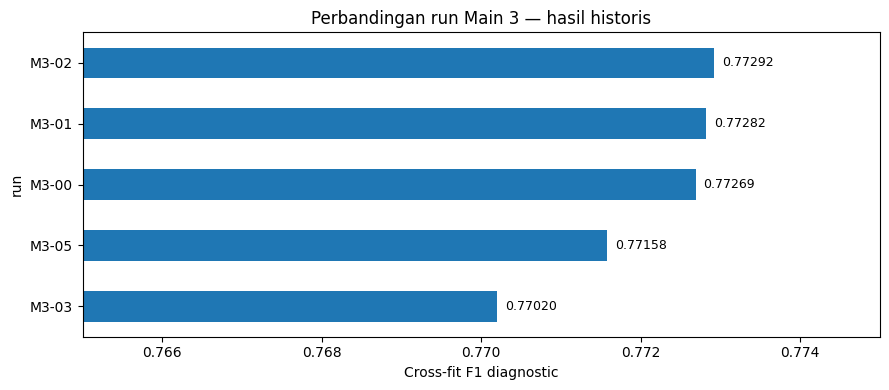

In [15]:
# 12. Visualisasi perbandingan historis (bukan hasil rerun)
HISTORICAL_RESULTS = pd.DataFrame([
    dict(run='M3-02',features=93,roc_auc=.845422, f1_group_oof=.774403,crossfit_selected_f1=.772923),
    dict(run='M3-01',features=95,roc_auc=.845273, f1_group_oof=.774107,crossfit_selected_f1=.772821),
    dict(run='M3-00',features=88,roc_auc=.845031, f1_group_oof=.774029,crossfit_selected_f1=.772687),
    dict(run='M3-05',features=95,roc_auc=.845209, f1_group_oof=.772817,crossfit_selected_f1=.771577),
    dict(run='M3-03',features=93,roc_auc=.842036, f1_group_oof=.771559,crossfit_selected_f1=.770201),
])
ax=HISTORICAL_RESULTS.set_index('run')['crossfit_selected_f1'].sort_values().plot.barh(figsize=(9,4))
ax.set(xlabel='Cross-fit F1 diagnostic',title='Perbandingan run Main 3 — hasil historis')
for p in ax.patches: ax.text(p.get_width()+.0001,p.get_y()+p.get_height()/2,f'{p.get_width():.5f}',va='center',fontsize=9)
ax.set_xlim(0.765,0.775);plt.tight_layout()
plt.savefig(FIG_DIR/'05_historical_model_comparison.png',dpi=160,bbox_inches='tight');plt.show()
HISTORICAL_RESULTS.to_csv(OUTPUT_DIR/'historical_results_main3.csv',index=False)

## 5. Model training — LightGBM + CatBoost, 5-fold Stratified CV

- Model LightGBM menerima encoding one-hot per training fold demi stabilitas Windows; kolom valid/test direindex ke kolom training.
- CatBoost menerima kategori string dan imputasi numerik berbasis median *training fold* saja.
- Bobot probabilitas: **0.75 LightGBM + 0.25 CatBoost**. M3-02 tetap model **global**, bukan scored-specialist (itu dikembangkan baru pada Main 4).
- Threshold tidak menentukan fitting, hanya konversi probabilitas → label setelah OOF diperoleh.

**Estimasi beban:** Mode `winner`: 5 fold × 2 model = **10 fit**. Mode `all`: empat run non-split + M3-03 terpisah dua grup = **60 fit classifier**, ditambah regressor M3-05. Jumlah ini lebih berat daripada sekadar M3-02.

In [16]:
# ============================================================
# CELL 7 — MODEL CONFIGURATION & TRAINING FUNCTIONS
# MAIN 3: EXPERIMENT SCORE 77
# FIX: LIGHTGBM WINDOWS ACCESS VIOLATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, CatBoostRegressor

# ============================================================
# 1. GLOBAL CONFIGURATION
# ============================================================

SEED = 42
N_SPLITS = 5

BLEND_LGBM = 0.75

LGB_ESTIMATORS = 650
CB_ITERATIONS = 650
IMPUTE_ITERATIONS = 350

CV = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

y = train[TARGET].astype(int).to_numpy()

score_group_train = (
    train["has_score"].astype(int).to_numpy()
)

score_group_test = (
    test["has_score"].astype(int).to_numpy()
)

assert set(np.unique(score_group_train)) <= {0, 1}
assert set(np.unique(score_group_test)) <= {0, 1}

SPLITS = list(
    CV.split(np.zeros(len(y)), y)
)

print("CV configuration initialized.")
print("Number of folds:", N_SPLITS)
print("Training rows:", len(y))

# ============================================================
# 2. MODEL FRAME PREPROCESSING
# ============================================================

def prepare_model_frames(x_train, x_val, x_test):

    tr, va, te = [
        frame.copy().reset_index(drop=True)
        for frame in (x_train, x_val, x_test)
    ]

    # Detect categorical columns
    cats = [
        c for c in tr.columns
        if (
            pd.api.types.is_object_dtype(tr[c])
            or isinstance(tr[c].dtype, pd.CategoricalDtype)
            or pd.api.types.is_string_dtype(tr[c])
        )
    ]

    nums = [
        c for c in tr.columns
        if c not in cats
    ]

    # ------------------------------------------
    # Clean categorical and numerical features
    # ------------------------------------------

    for frame in (tr, va, te):

        for col in cats:
            frame[col] = (
                frame[col]
                .fillna("Missing")
                .astype(str)
                .replace({
                    "nan": "Missing",
                    "None": "Missing"
                })
            )

        for col in nums:
            frame[col] = (
                pd.to_numeric(
                    frame[col],
                    errors="coerce"
                )
                .replace(
                    [np.inf, -np.inf],
                    np.nan
                )
            )

    # ------------------------------------------
    # LightGBM preprocessing
    # ------------------------------------------

    ltr = tr.copy()
    lva = va.copy()
    lte = te.copy()

    for col in cats:

        categories = sorted(
            tr[col].unique().tolist()
        )

        dtype = pd.CategoricalDtype(
            categories=categories
        )

        for frame in (ltr, lva, lte):
            frame[col] = frame[col].astype(dtype)

    # ------------------------------------------
    # CatBoost preprocessing
    # ------------------------------------------

    ctr = tr.copy()
    cva = va.copy()
    cte = te.copy()

    if nums:

        medians = (
            ctr[nums]
            .median(numeric_only=True)
            .fillna(0)
        )

        for frame in (ctr, cva, cte):
            frame[nums] = (
                frame[nums]
                .fillna(medians)
                .fillna(0)
                .astype(float)
            )

    return (
        (ltr, lva, lte),
        (ctr, cva, cte),
        cats
    )

# ============================================================
# 3. SAFE LIGHTGBM ENCODING
# ============================================================

def encode_lightgbm_frames(ltr, lva, lte, cats):

    # One-hot encoding to avoid native categorical
    # handling issues in LightGBM on Windows.

    encoded_train = pd.get_dummies(
        ltr,
        columns=cats,
        dtype=np.float32
    )

    feature_columns = encoded_train.columns

    encoded_val = pd.get_dummies(
        lva,
        columns=cats,
        dtype=np.float32
    )

    encoded_test = pd.get_dummies(
        lte,
        columns=cats,
        dtype=np.float32
    )

    # Align feature columns with training data
    encoded_val = encoded_val.reindex(
        columns=feature_columns,
        fill_value=0.0
    )

    encoded_test = encoded_test.reindex(
        columns=feature_columns,
        fill_value=0.0
    )

    # Convert to contiguous NumPy arrays
    X_train = np.ascontiguousarray(
        encoded_train.to_numpy(
            dtype=np.float32,
            na_value=np.nan
        )
    )

    X_val = np.ascontiguousarray(
        encoded_val.to_numpy(
            dtype=np.float32,
            na_value=np.nan
        )
    )

    X_test = np.ascontiguousarray(
        encoded_test.to_numpy(
            dtype=np.float32,
            na_value=np.nan
        )
    )

    # Validation
    assert X_train.shape[1] == X_val.shape[1]
    assert X_train.shape[1] == X_test.shape[1]

    if np.isinf(X_train).any():
        raise ValueError("Infinity found in LightGBM train")

    return X_train, X_val, X_test

# ============================================================
# 4. LIGHTGBM + CATBOOST ENSEMBLE
# ============================================================

def fit_predict_blend(
    xtr,
    xv,
    xt,
    ytr,
    seed=SEED
):

    # ------------------------------------------
    # Prepare model frames
    # ------------------------------------------

    (
        (ltr, lva, lte),
        (ctr, cva, cte),
        cats
    ) = prepare_model_frames(
        xtr,
        xv,
        xt
    )

    # ------------------------------------------
    # Encode LightGBM features
    # ------------------------------------------

    (
        X_lgb_train,
        X_lgb_val,
        X_lgb_test
    ) = encode_lightgbm_frames(
        ltr,
        lva,
        lte,
        cats
    )

    y_train = np.asarray(
        ytr,
        dtype=np.int32
    )

    # ==========================================
    # LIGHTGBM
    # ==========================================

    lgb = LGBMClassifier(
        n_estimators=LGB_ESTIMATORS,
        learning_rate=0.035,
        num_leaves=25,
        colsample_bytree=0.85,
        subsample=0.85,
        subsample_freq=1,
        reg_lambda=7,
        reg_alpha=0.2,
        min_child_samples=35,
        random_state=seed,
        verbosity=-1,
        n_jobs=1,
        force_col_wise=True
    )

    lgb.fit(
        X_lgb_train,
        y_train
    )

    lgb_val_pred = (
        lgb.predict_proba(X_lgb_val)[:, 1]
    )

    lgb_test_pred = (
        lgb.predict_proba(X_lgb_test)[:, 1]
    )

    # ==========================================
    # CATBOOST
    # ==========================================

    cb = CatBoostClassifier(
        iterations=CB_ITERATIONS,
        depth=6,
        learning_rate=0.035,
        l2_leaf_reg=7,
        loss_function="Logloss",
        random_seed=seed,
        verbose=False,
        thread_count=2,
        allow_writing_files=False
    )

    cb.fit(
        ctr,
        y_train,
        cat_features=cats
    )

    cb_val_pred = (
        cb.predict_proba(cva)[:, 1]
    )

    cb_test_pred = (
        cb.predict_proba(cte)[:, 1]
    )

    # ==========================================
    # ENSEMBLE
    # ==========================================

    val_pred = (
        BLEND_LGBM * lgb_val_pred
        + (1 - BLEND_LGBM) * cb_val_pred
    )

    test_pred = (
        BLEND_LGBM * lgb_test_pred
        + (1 - BLEND_LGBM) * cb_test_pred
    )

    assert np.isfinite(val_pred).all()
    assert np.isfinite(test_pred).all()

    return val_pred, test_pred

# ============================================================
# 5. INITIALIZATION SUMMARY
# ============================================================

print("=" * 55)
print("MAIN 3 — MODEL CONFIGURATION READY")
print("=" * 55)

print(f"Seed                : {SEED}")
print(f"Cross-validation    : {N_SPLITS} folds")
print(f"LightGBM estimators : {LGB_ESTIMATORS}")
print(f"CatBoost iterations : {CB_ITERATIONS}")
print(f"Imputation iterations: {IMPUTE_ITERATIONS}")
print(f"LightGBM blend      : {BLEND_LGBM:.0%}")
print(f"CatBoost blend      : {1-BLEND_LGBM:.0%}")
print("LightGBM encoding   : One-Hot / NumPy")
print("LightGBM threads    : 1")
print("CatBoost threads    : 2")

print("=" * 55)
print("CELL 7 INITIALIZED SUCCESSFULLY")
print("=" * 55)

CV configuration initialized.
Number of folds: 5
Training rows: 26086
MAIN 3 — MODEL CONFIGURATION READY
Seed                : 42
Cross-validation    : 5 folds
LightGBM estimators : 650
CatBoost iterations : 650
Imputation iterations: 350
LightGBM blend      : 75%
CatBoost blend      : 25%
LightGBM encoding   : One-Hot / NumPy
LightGBM threads    : 1
CatBoost threads    : 2
CELL 7 INITIALIZED SUCCESSFULLY


In [17]:
def add_foldwise_estimated_score(xtr,xv,xt,seed):
    # xtr/xv/xt adalah feature-engineered frames, avg_score missing jika has_score=0.
    non_score = [c for c in xtr.columns if ('score' not in c.lower()) and c!='has_score']
    scored = xtr['has_score'].eq(1) & xtr['avg_score'].notna()
    if scored.sum() < 30:
        raise RuntimeError('Insufficient scored training rows for regression')
    # Fit preprocessing berdasarkan training fold saja (bukan valid/test).
    (_,_,_), (ctr,cva,cte), cats = prepare_model_frames(xtr[non_score],xv[non_score],xt[non_score])
    reg = CatBoostRegressor(
        iterations=IMPUTE_ITERATIONS,depth=5,learning_rate=0.05,
        l2_leaf_reg=6,loss_function='RMSE',random_seed=seed,
        verbose=False,thread_count=-1,allow_writing_files=False)
    reg.fit(ctr.loc[scored.to_numpy()],xtr.loc[scored,'avg_score'].to_numpy(),cat_features=cats)
    out=[]
    for original, prepared in ((xtr,ctr),(xv,cva),(xt,cte)):
        f = original.copy().reset_index(drop=True)
        f['estimated_avg_score'] = f['avg_score'].astype(float)
        missing = f['has_score'].eq(0)
        if missing.any():
            f.loc[missing,'estimated_avg_score'] = np.clip(reg.predict(prepared.loc[missing]),0,100)
        f['estimated_avg_score_was_imputed'] = missing.astype('int8')
        out.append(f)
    return out

### Pilih mode training sebelum menjalankan cell berikut

`TRAIN_MODE='winner'` (default) cukup untuk notebook final M3-02 dan submission ulang. Pilih `TRAIN_MODE='all'` untuk mengulang seluruh ablation historis. **Tidak ada hasil training yang disisipkan sebagai output palsu.**

In [18]:
# Pilihan pengguna: 'winner' / 'all'. Default adalah reproduksi M3-02.
TRAIN_MODE = 'winner'
assert TRAIN_MODE in {'winner', 'all'}
RUNS_TO_TRAIN = (['M3-02'] if TRAIN_MODE == 'winner' else
                 ['M3-00','M3-01','M3-02','M3-03','M3-05'])
OOF_RESULTS = {}

for run_id in RUNS_TO_TRAIN:
    X_train, X_test = get_m3_frames(run_id)
    oof = np.full(len(X_train), np.nan, dtype=float)
    test_prob = np.zeros(len(X_test), dtype=float)
    fold_ids = np.full(len(X_train), -1, dtype=int)
    print(f'\n===== {run_id} | {X_train.shape[1]} features =====')
    for fold,(it,iv) in enumerate(SPLITS):
        xt, xv = X_train.iloc[it].copy(),X_train.iloc[iv].copy()
        xte = X_test.copy()
        if run_id == 'M3-05':
            xt,xv,xte = add_foldwise_estimated_score(xt,xv,xte,SEED+fold)
        yp = y[it]
        if run_id == 'M3-03':
            pv = np.full(len(iv),np.nan)
            pt = np.full(len(X_test),np.nan)
            for g in (0,1):
                mtr = score_group_train[it]==g
                mval = score_group_train[iv]==g
                mtest = score_group_test==g
                if not (mval.any() and mtest.any()):
                    raise ValueError('Kelompok kosong; cek distribusi has_score.')
                v,t = fit_predict_blend(
                    xt.iloc[np.where(mtr)[0]],xv.iloc[np.where(mval)[0]],
                    xte.iloc[np.where(mtest)[0]],yp[mtr],SEED+fold)
                pv[mval],pt[mtest] = v,t
        else:
            pv,pt = fit_predict_blend(xt,xv,xte,yp,SEED+fold)
        assert np.isfinite(pv).all() and np.isfinite(pt).all()
        oof[iv] = pv
        test_prob += pt / N_SPLITS
        fold_ids[iv] = fold
        print(f'Fold {fold+1}: F1@0.35 = {f1_score(y[iv],pv>=0.35):.5f}, AUC={roc_auc_score(y[iv],pv):.5f}')
    assert np.isfinite(oof).all() and (fold_ids>=0).all()
    OOF_RESULTS[run_id] = dict(oof=oof,test=test_prob,fold_ids=fold_ids)
print('Training selesai:',list(OOF_RESULTS))


===== M3-02 | 93 features =====
Fold 1: F1@0.35 = 0.76707, AUC=0.84121
Fold 2: F1@0.35 = 0.77953, AUC=0.85411
Fold 3: F1@0.35 = 0.77582, AUC=0.84784
Fold 4: F1@0.35 = 0.77118, AUC=0.83979
Fold 5: F1@0.35 = 0.76987, AUC=0.84440
Training selesai: ['M3-02']


In [19]:
# 13. Evaluasi OOF per-fold dan confusion untuk threshold frozen M3-02
from sklearn.metrics import confusion_matrix
if 'M3-02' not in OOF_RESULTS: raise RuntimeError('Run M3-02 belum dilatih.')
selected_oof=OOF_RESULTS['M3-02']['oof']
fold_ids=OOF_RESULTS['M3-02']['fold_ids']
chosen_label=np.where(score_group_train==0,selected_oof>=.420,selected_oof>=.370).astype(int)
fold_metrics=[]
for fold in sorted(np.unique(fold_ids)):
    m=fold_ids==fold
    tn,fp,fn,tp=confusion_matrix(y[m],chosen_label[m],labels=[0,1]).ravel()
    fold_metrics.append(dict(fold=int(fold)+1,n=int(m.sum()),f1=f1_score(y[m],chosen_label[m]),
        auc=roc_auc_score(y[m],selected_oof[m]),precision=precision_score(y[m],chosen_label[m],zero_division=0),
        recall=recall_score(y[m],chosen_label[m],zero_division=0),TP=int(tp),FP=int(fp),FN=int(fn),TN=int(tn)))
fold_metrics=pd.DataFrame(fold_metrics)
display(fold_metrics)
fold_metrics.to_csv(OUTPUT_DIR/'hasil_folds_main3_full.csv',index=False)
print('M3-02 OOF F1 (threshold frozen .420/.370):', f1_score(y,chosen_label))
print('M3-02 OOF AUC:',roc_auc_score(y,selected_oof))

,fold,n,f1,auc,precision,recall,TP,FP,FN,TN
0,1,5218,0.769991,0.841208,0.725112,0.820792,2258,856,493,1611
1,2,5217,0.780546,0.854109,0.739980,0.825818,2271,798,479,1669
2,3,5217,0.778553,0.847838,0.731840,0.831636,2287,838,463,1629
3,4,5217,0.768675,0.839789,0.729977,0.811705,2233,826,518,1640
4,5,5217,0.774238,0.844403,0.732102,0.821519,2260,827,491,1639


M3-02 OOF F1 (threshold frozen .420/.370): 0.7744033964460575
M3-02 OOF AUC: 0.845421812805838


## 6. Pemilihan threshold dan evaluasi model

**Bedakan tiga angka:**
1. **Apparent OOF F1:** threshold dipilih dari OOF yang sama, cenderung optimistis.
2. **Cross-fit threshold diagnostic:** threshold per fold dipilih memakai OOF empat fold lain, kemudian diterapkan pada fold yang ditahan; ini lebih konservatif tetapi **bukan nested CV murni**.
3. **Kaggle leaderboard F1:** diperoleh dari label tersembunyi test dan tidak dapat dihitung ulang dari `test.csv`.

Submission M3-02 historis menggunakan **threshold grup 0.420/0.370**, sehingga notebook ini mempertahankannya saat membuat submission (bukan melakukan tuning baru untuk memanfaatkan screenshot leaderboard).

In [20]:
THRESHOLDS = np.round(np.arange(.20,.651,.005),3)

def best_global_threshold(y_true,prob):
    pred = prob[None,:] >= THRESHOLDS[:,None]
    tp = (pred & (y_true[None,:] == 1)).sum(axis=1)
    n_pred = pred.sum(axis=1)
    scores = 2*tp / np.maximum(n_pred+int(y_true.sum()),1)
    k = int(np.argmax(scores))
    return float(THRESHOLDS[k]),float(scores[k])

def best_group_thresholds(y_true,prob,group):
    summary=[]
    for g in (0,1):
        yy=y_true[group==g]; pp=prob[group==g]
        pred=pp[None,:]>=THRESHOLDS[:,None]
        summary.append(((pred & (yy[None,:]==1)).sum(axis=1),pred.sum(axis=1)))
    (tp0,n0),(tp1,n1)=summary
    scores=2*(tp0[:,None]+tp1[None,:])/np.maximum(n0[:,None]+n1[None,:]+int(y_true.sum()),1)
    i,j=np.unravel_index(np.argmax(scores),scores.shape)
    return (float(THRESHOLDS[i]),float(THRESHOLDS[j])),float(scores[i,j])

def apply_group_thresholds(prob,group,t0,t1):
    return np.where(group==0,prob>=t0,prob>=t1).astype(int)

def evaluate_thresholds(y_true,prob,group,fold_id):
    global_thr,apparent_global=best_global_threshold(y_true,prob)
    (g0,g1),apparent_group=best_group_thresholds(y_true,prob,group)
    global_pred=np.zeros(len(y_true),dtype=int)
    group_pred=np.zeros(len(y_true),dtype=int)
    for fold in np.unique(fold_id):
        hold=fold_id==fold
        dev=~hold
        tg,_=best_global_threshold(y_true[dev],prob[dev])
        (t0,t1),_=best_group_thresholds(y_true[dev],prob[dev],group[dev])
        global_pred[hold]=(prob[hold]>=tg).astype(int)
        group_pred[hold]=apply_group_thresholds(prob[hold],group[hold],t0,t1)
    return dict(global_threshold=global_thr,group0_threshold=g0,group1_threshold=g1,
                apparent_global_f1=apparent_global,apparent_group_f1=apparent_group,
                crossfit_global_f1=f1_score(y_true,global_pred),
                crossfit_group_f1=f1_score(y_true,group_pred),
                auc=roc_auc_score(y_true,prob),
                global_oof_predictions=(prob>=global_thr).astype(int),
                group_oof_predictions=apply_group_thresholds(prob,group,g0,g1))

In [21]:
rows=[]
THRESHOLD_REPORT={}
for run_id,info in OOF_RESULTS.items():
    ev=evaluate_thresholds(y,info['oof'],score_group_train,info['fold_ids'])
    THRESHOLD_REPORT[run_id]=ev
    global_is_better=ev['crossfit_global_f1']>=ev['crossfit_group_f1']
    decision='global' if global_is_better else 'group'
    chosen=ev['global_oof_predictions'] if global_is_better else ev['group_oof_predictions']
    rows.append(dict(run=run_id,features=get_m3_frames(run_id)[0].shape[1] + (2 if run_id=='M3-05' else 0),
        roc_auc=ev['auc'],f1_global_oof=ev['apparent_global_f1'],f1_group_oof=ev['apparent_group_f1'],
        crossfit_global_f1=ev['crossfit_global_f1'],crossfit_group_f1=ev['crossfit_group_f1'],
        selected_decision=decision,crossfit_selected_f1=max(ev['crossfit_global_f1'],ev['crossfit_group_f1']),
        precision=precision_score(y,chosen),recall=recall_score(y,chosen),
        threshold_global=ev['global_threshold'],threshold_group0=ev['group0_threshold'],
        threshold_group1=ev['group1_threshold']))
results=pd.DataFrame(rows).sort_values('crossfit_selected_f1',ascending=False).reset_index(drop=True)
display(results.round(5))
BEST_RUN=results.iloc[0]['run']
BEST_DECISION=results.iloc[0]['selected_decision']
print('BEST:',BEST_RUN,'decision:',BEST_DECISION)
print('PERHATIAN: M3-00 mungkin TIDAK sama dengan F1 0.772849 Main 2 karena script model Main 2 tidak diunggah.')

,run,features,roc_auc,f1_global_oof,f1_group_oof,crossfit_global_f1,crossfit_group_f1,selected_decision,crossfit_selected_f1,precision,recall,threshold_global,threshold_group0,threshold_group1
0,M3-02,93,0.84542,0.77364,0.7744,0.77269,0.77292,group,0.77292,0.73178,0.82229,0.375,0.42,0.37


BEST: M3-02 decision: group
PERHATIAN: M3-00 mungkin TIDAK sama dengan F1 0.772849 Main 2 karena script model Main 2 tidak diunggah.


In [22]:
# 14. Bandingkan rerun dengan catatan historis, tanpa mengklaim skor pasti identik
historical_map=HISTORICAL_RESULTS.set_index('run')
comparison=[]
for r in results['run']:
    got=results.set_index('run').loc[r]
    base=historical_map.loc[r]
    comparison.append(dict(run=r,
        historical_f1=float(base['f1_group_oof']),rerun_f1=float(got['f1_group_oof']),
        delta_f1=float(got['f1_group_oof']-base['f1_group_oof']),
        historical_auc=float(base['roc_auc']),rerun_auc=float(got['roc_auc'])))
comparison=pd.DataFrame(comparison)
display(comparison)
comparison.to_csv(OUTPUT_DIR/'reproduction_comparison_main3.csv',index=False)
if not np.allclose(comparison['delta_f1'],0,atol=5e-5):
    print('PERHATIAN: rerun berbeda dari historis. Periksa data, pustaka, dan source; jangan klaim exact reproduction.')

,run,historical_f1,rerun_f1,delta_f1,historical_auc,rerun_auc
0,M3-02,0.774403,0.774403,3.964461e-07,0.845422,0.845422


In [23]:
from sklearn.metrics import confusion_matrix
for run_id in [r for r in ('M3-00','M3-02',BEST_RUN) if r in OOF_RESULTS]:
    info=OOF_RESULTS[run_id]; ev=THRESHOLD_REPORT[run_id]
    choice='global' if ev['crossfit_global_f1'] >= ev['crossfit_group_f1'] else 'group'
    pred=ev['global_oof_predictions'] if choice=='global' else ev['group_oof_predictions']
    print(f'\n{run_id}, {choice}: apparent F1 {f1_score(y,pred):.5f}, group thresholds {ev["group0_threshold"]}, {ev["group1_threshold"]}')
    for g in (0,1):
        m=score_group_train==g
        print('has_score',g,'n',m.sum(),'F1',round(f1_score(y[m],pred[m]),5),
              'precision',round(precision_score(y[m],pred[m],zero_division=0),5),
              'recall',round(recall_score(y[m],pred[m],zero_division=0),5),
              'CM',confusion_matrix(y[m],pred[m]).tolist())


M3-02, group: apparent F1 0.77440, group thresholds 0.42, 0.37
has_score 0 n 10046 F1 0.89247 precision 0.87364 recall 0.91214 CM [[1878, 952], [634, 6582]]
has_score 1 n 16040 F1 0.65394 precision 0.59684 recall 0.72311 CM [[6310, 3193], [1810, 4727]]

M3-02, group: apparent F1 0.77440, group thresholds 0.42, 0.37
has_score 0 n 10046 F1 0.89247 precision 0.87364 recall 0.91214 CM [[1878, 952], [634, 6582]]
has_score 1 n 16040 F1 0.65394 precision 0.59684 recall 0.72311 CM [[6310, 3193], [1810, 4727]]


,group,error_type,n
0,0,FN,634
1,0,FP,952
2,0,correct,8460
3,1,FN,1810
4,1,FP,3193
5,1,correct,11037


,code_module,error_type,n
0,M01,FN,87
1,M01,FP,72
2,M01,correct,443
3,M02,FN,596
4,M02,FP,1048
5,M02,correct,4724
6,M03,FN,210
7,M03,FP,572
8,M03,correct,2786
9,M04,FN,582


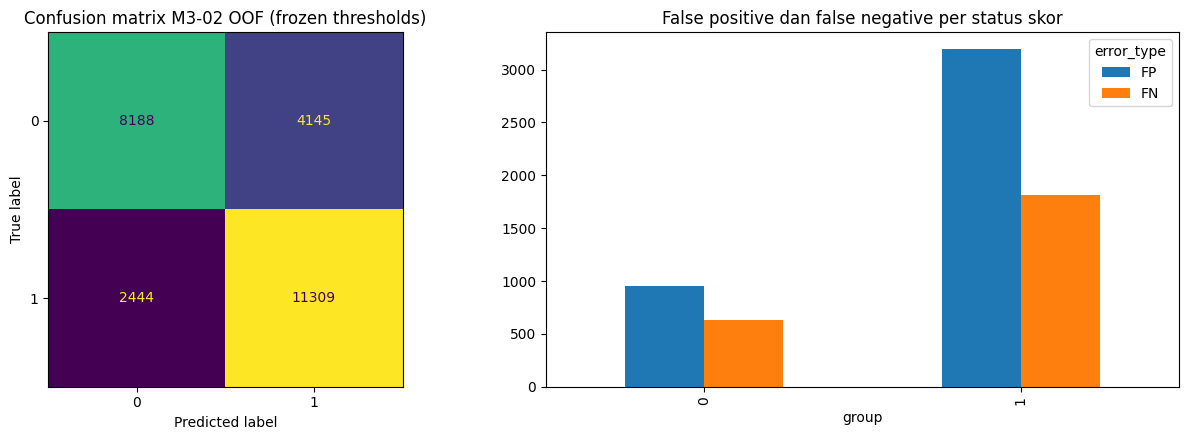

In [24]:
# 15. Confusion matrix / analisis kesalahan OOF M3-02
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display
err_df=train[[ID_COL,TARGET,'has_score','code_module','avg_score','interaction_volume','no_submission_by_cutoff']].copy()
err_df['oof_probability']=selected_oof
err_df['oof_pred']=chosen_label
err_df['error_type']=np.select([(y==0)&(chosen_label==1),(y==1)&(chosen_label==0)], ['FP','FN'],default='correct')
err_by_group=(err_df.assign(group=err_df['has_score'].astype(str))
   .groupby(['group','error_type']).size().rename('n').reset_index())
err_by_module=(err_df.groupby(['code_module','error_type']).size().rename('n').reset_index())
display(err_by_group,err_by_module)
err_df.to_csv(OUTPUT_DIR/'oof_error_analysis_main3.csv',index=False)
err_by_group.to_csv(OUTPUT_DIR/'error_groups_main3.csv',index=False)
err_by_module.to_csv(OUTPUT_DIR/'error_modules_main3.csv',index=False)

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
ConfusionMatrixDisplay.from_predictions(y,chosen_label,ax=axes[0],colorbar=False)
axes[0].set_title('Confusion matrix M3-02 OOF (frozen thresholds)')
err_by_group.pivot(index='group',columns='error_type',values='n').fillna(0)[['FP','FN']].plot.bar(ax=axes[1])
axes[1].set_title('False positive dan false negative per status skor')
plt.tight_layout();plt.savefig(FIG_DIR/'06_errors_main3.png',dpi=160,bbox_inches='tight');plt.show()

## 7. Keputusan final dan leaderboard yang tercatat

**Mengapa M3-02 dipilih?** Ia memiliki *cross-fit threshold F1 diagnostic* tertinggi di antara lima variasi Main 3 (**0.772923**) dengan 93 fitur. Memisahkan model (`M3-03`) maupun imputasi skor (`M3-05`) tidak meningkatkan metrik pembanding pada setup ini. Threshold grup menghasilkan F1 OOF **0.774403** (apparent); kelompok scored tetap lebih sulit.

**Hasil kompetisi yang dilaporkan:**
- File: `submission_m3_02_group.csv` (6.502 prediksi; **3.813** prediksi berisiko pada submission historis).
- Skor publik sebelumnya terkonfirmasi **0.78393**; screenshot leaderboard akhir juga menampilkan **0.78000**. Jenis kolom skor terakhir perlu dipastikan lewat header leaderboard, sehingga keduanya tidak dianggap berasal dari validasi notebook.
- Tidak ada klaim bahwa rerun notebook ini pasti mencetak 0.78393/0.78000 tanpa memeriksa kesamaan file submission dan lingkungan.

In [25]:
# 16. Hasil akhir M3-02: simpan submission tanpa menimpa file historis
# Threshold sengaja frozen dari run Main 3 asli (bukan dituning ulang dari leaderboard).
SUBMIT_RUN = 'M3-02'
FINAL_GROUP_THRESHOLDS = (0.420, 0.370)
probs = OOF_RESULTS[SUBMIT_RUN]['test']
final_pred = apply_group_thresholds(probs, score_group_test, *FINAL_GROUP_THRESHOLDS)
submission = sample_submission.copy()
submission[TARGET] = final_pred
assert submission.columns.tolist() == [ID_COL,TARGET]
assert submission[ID_COL].astype(str).tolist() == test[ID_COL].astype(str).tolist()
assert submission[TARGET].isin([0,1]).all()
assert len(submission) == len(test)
submission_file = OUTPUT_DIR / 'submission_m3_02_group_rerun.csv'
submission.to_csv(submission_file,index=False)
results.to_csv(OUTPUT_DIR/'hasil_models_main3_rerun.csv',index=False)
print('Submission:', submission_file)
print('Positif =',int(final_pred.sum()),'dari',len(final_pred))

# Perbandingan opsional terhadap file historis M3-02 jika tersedia di proyek.
import zipfile, io
reference=None; ref_location=None
candidate_paths = [DATA_DIR/'submission_m3_02_group.csv',
                   DATA_DIR/'main 3'/'submission_m3_02_group.csv']
for candidate in candidate_paths:
    if candidate.is_file():
        reference=pd.read_csv(candidate);ref_location=str(candidate);break
if reference is None:
    for archive_path in [DATA_DIR/'main 3.zip',DATA_DIR/'main3.zip']:
        if not archive_path.is_file(): continue
        with zipfile.ZipFile(archive_path) as z:
            entries=[n for n in z.namelist() if n.endswith('/submission_m3_02_group.csv') or n=='submission_m3_02_group.csv']
            if entries:
                reference=pd.read_csv(io.BytesIO(z.read(entries[0])))
                ref_location=f'{archive_path.name}::{entries[0]}'
                break
if reference is not None:
    if reference[ID_COL].astype(str).tolist()!=submission[ID_COL].astype(str).tolist():
        print('REFERENSI DITEMUKAN, tapi urutan ID berbeda:',ref_location)
    else:
        different=int((reference[TARGET].to_numpy()!=submission[TARGET].to_numpy()).sum())
        print('File referensi:',ref_location,'| perbedaan label:',different)
        if different!=0:
            print('Tidak boleh menganggap skor Kaggle historis berlaku untuk file rerun ini.')
else:
    print('File submission historis tidak ditemukan; perbandingan label dilewati.')

Submission: c:\Users\yosee\Documents\DSCO 2026\main3_full_analysis_outputs\submission_m3_02_group_rerun.csv
Positif = 3813 dari 6502
File referensi: main 3.zip::main 3/submission_m3_02_group.csv | perbedaan label: 0


In [26]:
# 17. Export laporan Markdown, gambar, tabel, checksum, dan ZIP dokumentasi
from datetime import datetime
import zipfile, json

def markdown_table(frame):
    try: return frame.to_markdown(index=False)
    except ImportError: return frame.to_string(index=False)

full_f1=f1_score(y,chosen_label)
full_auc=roc_auc_score(y,selected_oof)
final_status = {
    "model": "M3-02", "threshold_no_score":.420,"threshold_scored":.370,
    "train_n":int(len(train)),"test_n":int(len(test)),
    "rerun_oof_f1_fixed":float(full_f1),"rerun_oof_auc":float(full_auc),
    "submission_file":submission_file.name,"submission_sha256":sha256(submission_file),
    "historical_public_f1_reported":.78393,
    "additional_final_score_visible_on_screenshot":.78000,
    "note":"Nilai Kaggle historis tidak dihitung dari test labels di notebook; label reference comparison optional."
}
(OUTPUT_DIR/'run_summary.json').write_text(json.dumps(final_status,indent=2),encoding='utf-8')

report_lines=[
    '# DSCO 2026 — Main 3 Full Analysis',
    '', '## Problem & evaluation',
    'Predict student at_risk. Metric: binary F1. Data test tidak memiliki label.',
    '', '## EDA Summary',markdown_table(summary),
    '', '### Risiko per status skor',markdown_table(score_risk),
    '', '### Pola nilai 77',markdown_table(score_patterns),
    '', '### Aktivitas tidak konsisten',markdown_table(act_summary),
    '', '### Train-test shift',markdown_table(shift_summary),
    '', '## Cleaning & feature engineering',
    'Historical M2-06 normalization; mask scores when has_score=0; recompute inconsistent aggregates; 5 missingness interaction features in M3-02.',
    '', '### Feature register',markdown_table(features_table),
    '', '## Experimental design & historical evidence',markdown_table(HISTORICAL_RESULTS),
    '', '## Rerun results',markdown_table(results),
    '', '### Fold diagnostics',markdown_table(fold_metrics),
    '', '### Historical vs rerun',markdown_table(comparison),
    '', '### Error analysis',markdown_table(err_by_group),
    '', '## Selected candidate',
    f'M3-02; fixed group thresholds 0.420 / 0.370. Rerun F1 OOF {full_f1:.6f}, AUC {full_auc:.6f}.',
    'Historical public Kaggle F1 reported 0.78393; an additional 0.78000 score appeared on the final screenshot. These are external leaderboard results, not notebook-computed metrics.',
    '', '## Limitations',
    'The underlying feature generation timestamps and source mapping for GGG are not independently verified.',
    'Thresholds selected on full OOF can be optimistic; threshold cross-fit diagnostic is not nested validation.',
    'Model and feature engineering may be version-sensitive. A different rerun file may have a different Kaggle score.',
    '', '## Figures',
]
for img in sorted(FIG_DIR.glob('*.png')):
    report_lines += [f'![{img.stem}](figures/{img.name})','']
report_path=OUTPUT_DIR/'LAPORAN_MAIN3_LENGKAP.md'
report_path.write_text('\n\n'.join(report_lines),encoding='utf-8')
archive=OUTPUT_DIR/'MAIN3_FULL_ANALYSIS_RESULTS.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in OUTPUT_DIR.rglob('*'):
        if file.is_file() and file!=archive:
            z.write(file,arcname=file.relative_to(OUTPUT_DIR))
print('Markdown report:',report_path)
print('ZIP results:',archive)
print('Output files:',len([p for p in OUTPUT_DIR.rglob('*') if p.is_file()]))

Markdown report: c:\Users\yosee\Documents\DSCO 2026\main3_full_analysis_outputs\LAPORAN_MAIN3_LENGKAP.md
ZIP results: c:\Users\yosee\Documents\DSCO 2026\main3_full_analysis_outputs\MAIN3_FULL_ANALYSIS_RESULTS.zip
Output files: 28


## 8. Kesimpulan akhir (untuk laporan kompetisi)

**Main 3 menunjukkan bahwa representasi missingness yang kontekstual lebih efektif dibanding pengisian skor buatan atau memisahkan seluruh model per status skor pada eksperimen ini.** Dengan 5-fold stratified CV, M3-02 memperoleh skor *threshold cross-fit diagnostic* terbaik di antara variasi Main 3 (**0.772923** pada run historis) dan F1 OOF apparent dengan threshold grup **0.774403**. File submission historis memperoleh skor publik **0.78393**, sedangkan screenshot akhir juga menunjukkan nilai **0.78000**.

**Pelajaran metodologis:** jangan menyamakan pola nilai dominan dengan bukti kesalahan data; jangan memakai `at_risk` untuk menentukan imputasi; jangan menyamakan CV, public leaderboard, dan private leaderboard. Notebook ini mempertahankan keputusan asli Main 3 meskipun pekerjaan Main 4–8 selanjutnya menghasilkan insight baru.

**Artefak yang dibuat saat notebook dijalankan:** `main3_full_analysis_outputs/` berisi laporan Markdown, seluruh EDA grafik, tabel validasi, analisis error, manifest, dan submission *rerun* bernama berbeda dari submission historis.